# Assignment 2 — Problem IV: Temporal Extrapolation of Damage Dynamics

This notebook addresses Problem IV of Assignment 2 using temporal reduced-order models for U-bolt damage propagation. It includes DMD and SINDy identification, alternative reduced dynamics, independent test validation, and extrapolation to twice the observed time horizon using the parameters inferred in Problem III.


## 0. Libraries and numerical environment

Load the NumPy version compatible with PETSc before importing the finite-element libraries.


In [1]:
import sys

# Load the system NumPy version compatible with PETSc.
sys.path.insert(0, "/usr/lib/python3/dist-packages")
import numpy as np
sys.path.pop(0)

print("NumPy:", np.__version__, np.__file__)

# Check PETSc compatibility.
from petsc4py import PETSc
print("PETSc:", PETSc.Sys.getVersion())

from IPython.display import clear_output

NumPy: 1.26.4 /usr/lib/python3/dist-packages/numpy/__init__.py
PETSc: (3, 19, 6)


## 1. Problem formulation and methodology

### 1.1 Objective

Problem IV asks whether damage reaches $x^{\ast}=(3.5,2)$ at $t^{\ast}=2T=0.04$, and to what extent, using the parameters estimated in Problem III. The available FOM trajectories cover $[0,T]$, with $T=0.02$.

Damage propagation is described by the Fisher–KPP equation

$$
\partial_{t} u-D\Delta u=ru(1-u),
\qquad D=10^{\mu_{1}},\quad r=10^{\mu_{2}+2},\quad\delta=\mu_{3}+1,
$$

with homogeneous Neumann boundary conditions and initial damage $g_{\delta}$. The physical range is $0\leq u\leq1$. We distinguish numerically completed forecasts from predictions that are accurate and physically admissible.

### 1.2 Reduced representation

We reuse the mass-orthonormal POD basis from the preceding tasks:

$$
u_{h}(t;\mu)\approx V_{N}a(t;\mu),\qquad
V_{N}^{\top} MV_{N}=I,\qquad a=V_{N}^{\top} Mu_{h}.
$$

Here $M$ is the FEM mass matrix. Temporal models propagate the reduced coefficients, which are then reconstructed as FEM fields. We compare spatial projection error, autonomous prediction error, and pointwise damage; these quantities answer different questions.

### 1.3 Methods and evaluation protocol

DMD and continuous-time parametric SINDy are the main extrapolation approaches. POD-Galerkin, a hybrid correction, POD-LSTM and discrete-time SINDy provide additional comparisons to investigate the observed limitations.

The parameter split is **60 training, 15 validation and 25 test trajectories**, consistent with the 75 training/validation and 25 test cases required by the assignment. In the initial benchmark, dynamical identification uses $[0,T/2]$ and autonomous prediction is evaluated on $(T/2,T]$. DMD fits a separate operator to each observed trajectory; the parametric learned models reuse training-derived dynamics at new parameters.

**Scope of the temporal holdout.** The fixed POD basis was constructed from complete training trajectories over $[0,T]$. Thus, the holdout restricts the data used to identify temporal dynamics, while the spatial basis already represents later states from other training parameters. No test trajectories enter the POD construction.

We report FEM $L^{2}$ errors and completion rates, with separate statistics for $\mu_{2}\geq0.65$, the regime most relevant to the identified parameters. Conditional error statistics exclude failed forecasts and must be read alongside the failure counts.

For the final $T\to2T$ forecast, we use all available training times and initialize the models from the POD-NN history at $\mu_{\mathrm{opt}}$. This final horizon has no FOM reference in the comparisons presented below; reliability is assessed through model disagreement, completion and physical bounds.


### 1.4 Dataset loading and reduced coordinates

Load the FOM trajectories, the saved POD basis and the inverse-problem results. Reconstruct the FEM mass matrix and project the trajectories into the existing reduced space. The data-loading cell also restores the saved LSTM weighting and defines FEM point evaluation for the later diagnostics.


In [2]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import torch
import json
import dolfin as df
from pathlib import Path
from IPython.display import Image, display
import support_functions as sf
import extrapolation_functions as ef

# Load POD basis and inverse-problem results
artifacts = Path("artifacts")
Vn = np.load(artifacts / "pod_basis.npy")

with np.load(artifacts / "inverse_results.npz") as inverse:
    mu_opt = inverse["mu_opt"]
    sensor_times = inverse["sensor_times"]

# Load FOM trajectories
dataset_path = next(
    (p for p in [Path("FOMdata.npz"), Path("u-bolt.npz")] if p.exists()),
    None
)
if dataset_path is None:
    raise FileNotFoundError("FOM dataset not found.")

with np.load(dataset_path) as data:
    mu_fom = data["mu"]
    u_fom = data["u"]

# Reconstruct FEM mass matrix and project onto the existing POD basis
mesh, Vh = sf.build_ubolt_mesh(stepsize=0.05, knots=30)
M = sf.assemble_mass_matrix(Vh)

N_mu, N_t, N_h = u_fom.shape
N = Vn.shape[1]

assert Vh.dim() == N_h == Vn.shape[0]
assert N_t == len(sensor_times)

A_fom = sf.project_l2(
    u_fom.reshape(-1, N_h), Vn, M
).reshape(N_mu, N_t, N)

# Temporal identification / extrapolation split
split_idx = (N_t - 1) // 2
t_fit = sensor_times[:split_idx + 1]
t_forecast = sensor_times[split_idx + 1:]

T = float(sensor_times[-1])
dt = float(np.mean(np.diff(sensor_times)))

assert np.allclose(np.diff(sensor_times), dt)
assert np.isclose(sensor_times[split_idx], T / 2)

print(f"FOM: {N_mu} trajectories, {N_t} snapshots, {N_h} DOFs")
print(f"POD: {N} modes | coefficients: {A_fom.shape}")
print(f"Identification: [0, {t_fit[-1]:.4f}]")
print(f"Extrapolation: ({t_fit[-1]:.4f}, {T:.4f}]")
print(f"Target parameters: {mu_opt}")

# Recover the high-reaction weighting used by the saved LSTM checkpoint.

best_lstm_weight = torch.load(
    artifacts / "pod_lstm_best.pt",
    map_location="cpu",
    weights_only=False
)["config"]["weight_strength"]


def evaluate_fem_at_point(field, point):
    """Return the scalar FEM value at point after loading the field DOF vector into Vh."""
    f = df.Function(Vh)
    f.vector().set_local(np.asarray(field, dtype=float))
    f.vector().apply("insert")
    return float(f(df.Point(*point)))


FOM: 100 trajectories, 41 snapshots, 6636 DOFs
POD: 50 modes | coefficients: (100, 41, 50)
Identification: [0, 0.0100]
Extrapolation: (0.0100, 0.0200]
Target parameters: [0.4010064  0.89656759 0.89816353]


### 1.5 Reproducible parameter split

Use a fixed random permutation to assign 60 trajectories to training, 15 to validation and 25 to independent testing. The same indices are retained throughout temporal model selection and comparison.


In [3]:
# Reproducible parameter-space split (shared with subsequent methods)
rng = np.random.default_rng(115)
permutation = rng.permutation(N_mu)

n_train = int(0.60 * N_mu)
n_val = int(0.15 * N_mu)

train_idx = permutation[:n_train]
val_idx = permutation[n_train:n_train + n_val]
test_idx = permutation[n_train + n_val:]


## 2. Dynamic Mode Decomposition (DMD)

### 2.1 Methodology

DMD approximates consecutive POD states by a linear discrete-time evolution law. With snapshots from the identification interval,

$$
X=[a_{0},\ldots,a_{m-1}],\qquad Y=[a_{1},\ldots,a_{m}],
$$

we form the truncated SVD $X\approx U_{r}\Sigma_{r}V_{r}^{\top}$ and identify the projected operator

$$
\widetilde A=U_{r}^{\top} YV_{r}\Sigma_{r}^{-1}.
$$

The forecast evolves within the retained subspace:

$$
z_{0}=U_{r}^{\top} a_{m},\qquad z_{k+1}=\widetilde A z_{k},
\qquad\widehat a_{k}=U_{r}z_{k}.
$$

The POD dimension $N$ and DMD rank $r$ are distinct: $N$ controls spatial representation, while $r$ truncates the trajectory snapshot matrix. Each parameter-dependent trajectory has its own fitted operator. The method is inexpensive, but its fixed linear dynamics do not explicitly impose logistic saturation or physical damage bounds.


In [4]:
# Identify trajectory-specific DMD models and select a common
# truncation rank using training trajectories only.

N_mu, N_t, N = A_fom.shape

# Candidate ranks are limited by the number of snapshot pairs
ranks = np.arange(1, min(N, split_idx) + 1)

# Final-time extrapolation error for each trajectory and rank
final_errors = np.full((N_mu, len(ranks)), np.nan)

for i in range(N_mu):
    for j, rank in enumerate(ranks):
        try:
            _, prediction = ef.dmd_forecast(
                A_fom[i], rank=rank, split_idx=split_idx
            )
            error = ef.relative_coefficient_errors(
                A_fom[i, split_idx + 1:], prediction
            )
            final_errors[i, j] = 100 * error[-1]
        except ValueError:
            continue  # Numerically inadmissible rank

# Select one rank using the training set only
train_median = np.nanmedian(final_errors[train_idx], axis=0)
best_rank_idx = np.nanargmin(train_median)
r_dmd = int(ranks[best_rank_idx])

print(f"DMD rank candidates: {ranks[0]}–{ranks[-1]}")
print(f"Selected common rank: {r_dmd}")
print(f"Training median final error: {train_median[best_rank_idx]:.2f}%")
print(f"Train / validation / test: "
      f"{len(train_idx)} / {len(val_idx)} / {len(test_idx)}")


DMD rank candidates: 1–20
Selected common rank: 18
Training median final error: 5.79%
Train / validation / test: 60 / 15 / 25


### 2.2 Identification and rank selection

Each operator is fitted on $[0,T/2]$. A common rank is selected by minimizing the median final-time **coefficient error** over the training trajectories:

$$
r^{\ast}=\arg\min_{r}\operatorname{median}_{i\in\mathcal I_{\mathrm{train}}}
\frac{\|a_{i}(T)-\widehat a_{i}(T;r)\|_{2}}{\|a_{i}(T)\|_{2}}.
$$

The selected rank is $r=18$. It is held fixed for validation and test trajectories; their observed prefixes are used only to fit their individual operators. This coefficient metric measures discrepancy within the POD representation. The subsequent unified benchmark compares reconstructions against the full FEM solution and also includes spatial truncation error.


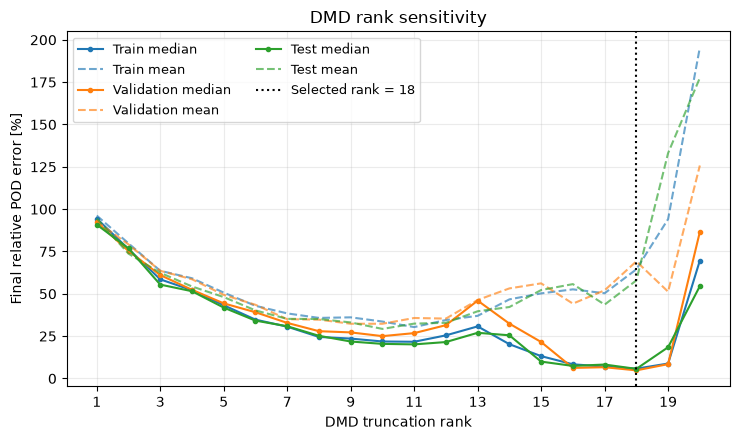

DMD benchmark | rank = 18
Split          Median [%]     Mean [%]      Max [%]
Train                5.79        64.46       473.83
Validation           4.80        69.16       319.36
Test                 5.67        57.93       418.62
mu1: Spearman rho = -0.109, p = 0.603
mu2: Spearman rho = +0.954, p = 1.66e-13
mu3: Spearman rho = -0.126, p = 0.548


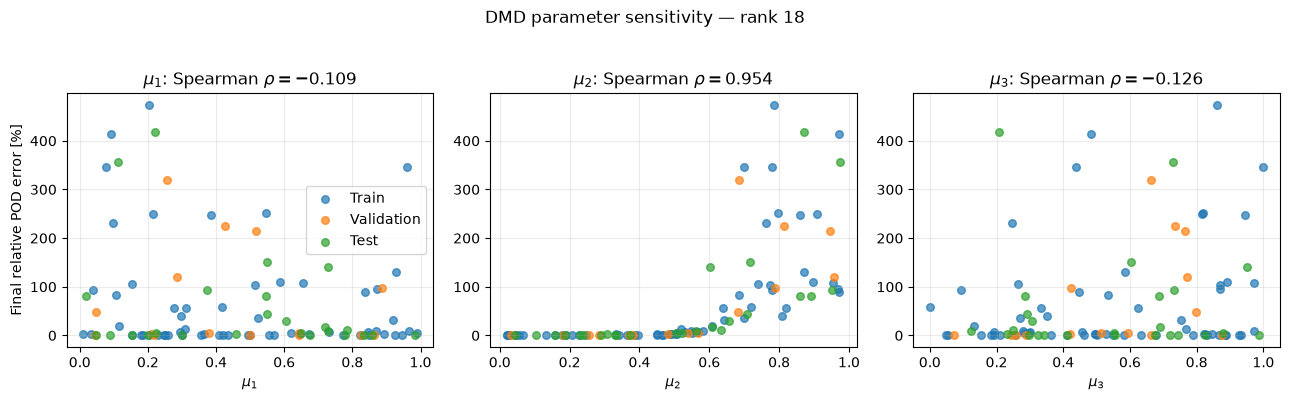

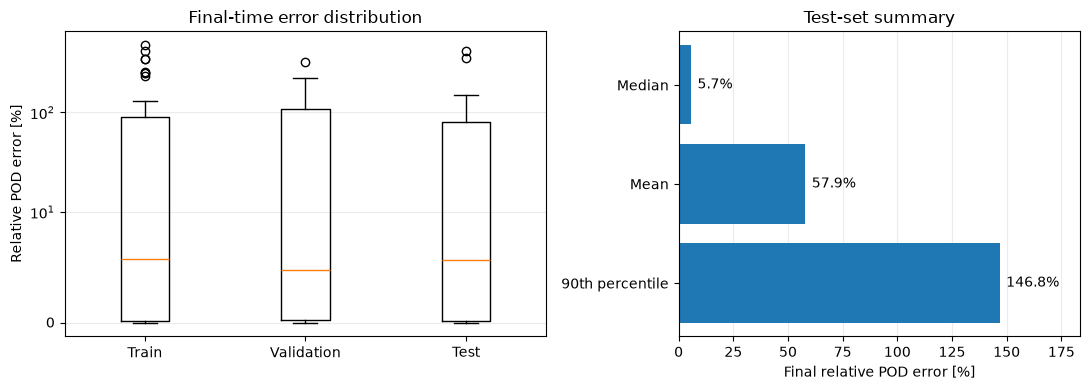

In [5]:
# Assess DMD rank sensitivity using mean and median final-time errors.
# The selected rank minimizes the training median, not the mean.
groups = {"Train": train_idx, "Validation": val_idx, "Test": test_idx}
fig, ax = plt.subplots(figsize=(7.5, 4.5))

for name, idx in groups.items():
    median_error = np.nanmedian(final_errors[idx], axis=0)
    mean_error = np.nanmean(final_errors[idx], axis=0)

    line, = ax.plot(
        ranks, median_error,
        marker="o", ms=3,
        label=f"{name} median"
    )

    ax.plot(
        ranks, mean_error,
        ls="--", alpha=0.65,
        color=line.get_color(),
        label=f"{name} mean"
    )

ax.axvline(
    r_dmd, color="black", ls=":",
    label=f"Selected rank = {r_dmd}"
)

ax.set(
    xlabel="DMD truncation rank",
    ylabel="Final relative POD error [%]",
    title="DMD rank sensitivity"
)

ax.set_xticks(ranks[::2])
ax.grid(alpha=0.25)
ax.legend(ncol=2, fontsize=9)

plt.tight_layout()
plt.show()

# Evaluate DMD extrapolation accuracy and correlate errors with all physical parameters.

from scipy.stats import spearmanr

dmd_errors = final_errors[:, best_rank_idx]
groups = {"Train": train_idx, "Validation": val_idx, "Test": test_idx}

print(f"DMD benchmark | rank = {r_dmd}")
print(f"{'Split':<12}{'Median [%]':>13}{'Mean [%]':>13}{'Max [%]':>13}")

for name, idx in groups.items():
    e = dmd_errors[idx]
    print(f"{name:<12}{np.nanmedian(e):>13.2f}"
          f"{np.nanmean(e):>13.2f}{np.nanmax(e):>13.2f}")

# Correlations are computed exclusively on the test set
test_errors = dmd_errors[test_idx]
valid = np.isfinite(test_errors)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

for j, ax in enumerate(axes):
    rho, p_value = spearmanr(
        mu_fom[test_idx[valid], j],
        test_errors[valid]
    )

    for name, idx in groups.items():
        ax.scatter(
            mu_fom[idx, j], dmd_errors[idx],
            label=name, s=30, alpha=0.7
        )

    ax.set(
        xlabel=rf"$\mu_{j+1}$",
        ylabel="Final relative POD error [%]" if j == 0 else "",
        title=rf"$\mu_{j+1}$: Spearman $\rho={rho:.3f}$"
    )
    ax.grid(alpha=0.25)

    print(f"mu{j+1}: Spearman rho = {rho:+.3f}, p = {p_value:.3g}")

axes[0].legend()
fig.suptitle(f"DMD parameter sensitivity — rank {r_dmd}", y=1.04)
fig.tight_layout()
plt.show()

# Distribution of final-time extrapolation errors

# Compare DMD error distributions and summarize test-set performance.

fig, axes = plt.subplots(
    1, 2, figsize=(11, 4),
    gridspec_kw={"width_ratios": [1.2, 1]}
)

# Error distribution across data splits
data = [dmd_errors[idx][np.isfinite(dmd_errors[idx])]
        for idx in groups.values()]

axes[0].boxplot(data, tick_labels=list(groups))
axes[0].set(
    title="Final-time error distribution",
    ylabel="Relative POD error [%]"
)
axes[0].set_yscale("symlog", linthresh=10)
axes[0].grid(axis="y", alpha=0.25)

# Summary statistics on the held-out test set
test_e = dmd_errors[test_idx]
test_e = test_e[np.isfinite(test_e)]

stats = {
    "Median": np.median(test_e),
    "Mean": np.mean(test_e),
    "90th percentile": np.percentile(test_e, 90),
}

bars = axes[1].barh(list(stats), list(stats.values()))
axes[1].invert_yaxis()
axes[1].set(
    title="Test-set summary",
    xlabel="Final relative POD error [%]"
)
axes[1].grid(axis="x", alpha=0.25)
axes[1].set_axisbelow(True)

for bar in bars:
    value = bar.get_width()
    axes[1].text(
        value + max(stats.values()) * 0.02,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}%",
        va="center"
    )

axes[1].set_xlim(0, max(stats.values()) * 1.25)

fig.tight_layout()
plt.show()


### 2.3 Results and discussion

The training rank study selects $r=18$; retaining the highest admissible ranks deteriorates prediction accuracy. This is consistent with sensitivity to small singular values, although rank sensitivity alone does not identify the cause of every large error.

On the test set, the median final coefficient error is **5.67%**, while the mean is **57.93%** and the maximum **418.62%**. The low median therefore conceals substantial failures in a subset of trajectories.

Errors are strongly associated with the reaction parameter: the test-set Spearman correlation with $\mu_{2}$ is approximately **0.954**, whereas associations with diffusion and initial damage location are weaker. This is consistent with difficulty reproducing the nonlinear reaction and saturation regime; it is an association, not a controlled attribution of error to one mechanism.

DMD is a useful baseline for favorable trajectories, but its aggregate median is insufficient evidence of reliability near the high-reaction target parameters.


### 2.4 Additional DMD diagnostics

**Transient exclusion.** Joint tuning of the starting snapshot and rank selects `start_idx=3`, $r=16$, but gives a test median coefficient error of **6.36%**, compared with **5.67%** for the baseline `start_idx=0`, $r=18$. Excluding the initial transient does not improve the overall median in this experiment.

**Tuning for high reaction.** A separate experiment defines high reaction using the training-set upper quartile, $\mu_{2}\geq0.7642$. It contains four validation and five test trajectories. The selected `start_idx=9`, $r=11$ reduces the median on those five test cases from **64.44% to 54.55%**, relative to the globally tuned transient-exclusion configuration (`start_idx=3`, $r=16$). These values are not directly comparable with the later benchmark using $\mu_{2}\geq0.65$ and baseline rank 18.

**Absolute-error check.** Examination of absolute errors and reference norms indicates that the largest relative errors represent substantial prediction discrepancies, rather than only small denominators.

These tests show that the explored rank and window adjustments do not establish reliable forecasts in the critical regime. They motivate a comparison with nonlinear dynamics.


## 3. Sparse Identification of Nonlinear Dynamics (SINDy)

### 3.1 Model and motivation

Unlike trajectory-specific DMD, continuous-time SINDy identifies one parameter-dependent vector field from multiple training trajectories. We retain $n$ POD coefficients and exploit the linear and quadratic structure of the Fisher–KPP equation:

$$
\dot a=ra+DBa+rQ(a,a).
$$

The known reaction contribution $ra$ is represented exactly for the mass-orthonormal POD coordinates. The remaining operators are estimated from data; exact representation of this linear term does not imply that the truncated dynamics are closed.

### 3.2 Physics-informed library

The regression uses diffusion-scaled linear and reaction-scaled quadratic features:

$$
\Theta(a,D,r)=
[D a_{1},\ldots,D a_{n},\;r a_{1}^{2},r a_{1}a_{2},\ldots,r a_{n}^{2}],
\qquad N_{\mathrm{features}}=n+\frac{n(n+1)}2.
$$

The targets are $Y=\dot a-ra$, so that $\Theta\Xi$ approximates the remaining vector field. Quadratic terms use unique index pairs; their coefficients absorb the corresponding cross-term multiplicities. The parameter $\delta$ affects the initial condition, rather than appearing explicitly in this evolution library.

### 3.3 Identification and evaluation

Derivatives are estimated by second-order finite differences, including one-sided formulas at the endpoints. Library columns are normalized before Ridge-regularized sequential thresholded least squares (STLSQ).

The candidate library reflects the PDE structure, but its operators need not be sparse in POD coordinates. Identification is also affected by correlated samples, derivative approximation and unresolved modes. We therefore evaluate both derivative fitting and autonomous integration from $T/2$ to $T$.


In [6]:
# Assess POD truncation accuracy and prepare the observed training trajectories
# for identifying a global parameter-dependent SINDy model.

candidate_modes = [5, 10, 15, 20, 30, 50]
projection_errors = []

for n in candidate_modes:
    u_ref = u_fom[train_idx].reshape(-1, N_h)
    a_n = A_fom[train_idx, :, :n].reshape(-1, n)
    u_n = sf.reconstruct_pod(a_n, Vn[:, :n])

    error = sf.relative_l2_error(u_ref, u_n, M)
    projection_errors.append(100 * np.mean(error))

print(f"{'Modes':>7} {'Projection error [%]':>22} {'SINDy features':>17}")
for n, error in zip(candidate_modes, projection_errors):
    features = n + n * (n + 1) // 2
    print(f"{n:7d} {error:22.2f} {features:17d}")

# Selected exploratory configuration
n_sindy = 20

# Use only snapshots in the identification interval [0, T/2]
Z_train = A_fom[train_idx, :split_idx + 1, :n_sindy]
mu_train = mu_fom[train_idx]

print(f"\nSINDy training trajectories: {Z_train.shape[0]}")
print(f"Observed snapshots: {Z_train.shape[1]}")
print(f"Reduced state dimension: {Z_train.shape[2]}")


  Modes   Projection error [%]    SINDy features
      5                  26.10                20
     10                  12.24                65
     15                   7.64               135
     20                   5.11               230
     30                   2.97               495
     50                   1.58              1325

SINDy training trajectories: 60
Observed snapshots: 21
Reduced state dimension: 20


**Reduced-dimension selection.** With 60 training trajectories and 21 identification snapshots, each reduced equation has 1260 regression observations. These are temporally correlated and should not be interpreted as 1260 independent samples.

At $n=50$, the library has 1325 features and the unregularized identification problem is underdetermined. We initially choose $n=20$, giving 230 features, and examine $n=10$ in additional experiments.

The displayed POD errors average over **all training snapshots on $[0,T]$**, rather than only the identification interval or final time. The approximately **5.11%** error at $n=20$ characterizes spatial reconstruction; it does not establish identifiability or extrapolation accuracy.


In [7]:
# Construct the physics-informed SINDy library from observed training trajectories.

n_sindy = 20

Z_train = A_fom[train_idx, :split_idx + 1, :n_sindy]
mu_train = mu_fom[train_idx]

Theta, Y_sindy, Z, Z_dot, r, quadratic_pairs = ef.build_sindy_library(
    Z_train, mu_train, dt
)

n_samples, n_features = Theta.shape

print(f"Reduced dimension: {n_sindy}")
print(f"Training trajectories: {len(train_idx)}")
print(f"Observed snapshots per trajectory: {Z_train.shape[1]}")
print(f"Regression observations: {n_samples}")
print(f"Library features: {n_features}")
print(f"Target matrix: {Y_sindy.shape}")
print(f"Regression samples/features: {n_samples / n_features:.2f}")


Reduced dimension: 20
Training trajectories: 60
Observed snapshots per trajectory: 21
Regression observations: 1260
Library features: 230
Target matrix: (1260, 20)
Regression samples/features: 5.48


In [8]:
# Identify the SINDy vector field and evaluate derivative fitting and sparsity.

alpha_sindy = 1e-4
threshold_sindy = 0.1

Xi_sindy, Xi_scaled, feature_norms = ef.fit_sindy(
    Theta, Y_sindy,
    alpha=alpha_sindy,
    threshold=threshold_sindy
)

Z_dot_pred = r[:, None] * Z + Theta @ Xi_sindy

derivative_error = (
    np.linalg.norm(Z_dot - Z_dot_pred)
    / np.linalg.norm(Z_dot)
)

n_active = np.count_nonzero(Xi_scaled)
n_total = Xi_scaled.size
sparsity = 100 * (1 - n_active / n_total)

print("=== SINDy identification ===")
print(f"Reduced dimension: {n_sindy}")
print(f"Ridge alpha: {alpha_sindy:.1e}")
print(f"STLSQ threshold: {threshold_sindy}")
print(f"Active coefficients: {n_active}/{n_total}")
print(f"Sparsity: {sparsity:.2f}%")
print(f"Relative derivative error: {100 * derivative_error:.2f}%")


=== SINDy identification ===
Reduced dimension: 20
Ridge alpha: 1.0e-04
STLSQ threshold: 0.1
Active coefficients: 4592/4600
Sparsity: 0.17%
Relative derivative error: 4.95%


In [9]:
# Validate temporal extrapolation by integrating SINDy from T/2 to T.
# Report failed integrations separately from successful predictions.

t_extrap = sensor_times[split_idx:]
sindy_val_errors = np.full(len(val_idx), np.inf)

for k, idx in enumerate(val_idx):
    z_reference = A_fom[idx, split_idx:, :n_sindy]
    z0 = z_reference[0]

    # Divergence threshold based only on the observed trajectory
    observed = A_fom[idx, :split_idx + 1, :n_sindy]
    reference_scale = max(
        np.max(np.linalg.norm(observed, axis=1)), 1e-12
    )

    z_pred = ef.simulate_sindy(
        z0=z0,
        mu=mu_fom[idx],
        Xi=Xi_sindy,
        t_eval=t_extrap,
        pairs=quadratic_pairs,
        max_norm=10 * reference_scale
    )

    if z_pred is not None:
        error = ef.relative_coefficient_errors(
            z_reference[1:], z_pred[1:]
        )
        sindy_val_errors[k] = 100 * error[-1]

success = np.isfinite(sindy_val_errors)
successful_errors = sindy_val_errors[success]

print("=== SINDy temporal validation ===")
print(f"Successful integrations: {success.sum()}/{len(val_idx)}")
print(f"Failed integrations: {(~success).sum()}")

if successful_errors.size:
    print(f"Median error (successful): {np.median(successful_errors):.2f}%")
    print(f"Mean error (successful): {np.mean(successful_errors):.2f}%")
    print(f"Maximum error (successful): {np.max(successful_errors):.2f}%")

if not success.all():
    print("Warning: error statistics exclude failed integrations.")


=== SINDy temporal validation ===
Successful integrations: 10/15
Failed integrations: 5
Median error (successful): 6.57%
Mean error (successful): 13.44%
Maximum error (successful): 80.46%


### 3.4 Regression accuracy and sparsity

Let $s_{j}$ be the norm of library column $j$, $\widetilde\Theta_{j}=\Theta_{j}/s_{j}$, and $\widetilde\Xi_{j}=s_{j}\Xi_{j}$. Ridge regression solves

$$
\min_{\widetilde\Xi}
\|Y-\widetilde\Theta\widetilde\Xi\|_{F}^{2}
+\alpha\|\widetilde\Xi\|_{F}^{2},
$$

followed by thresholding and refitting. Thus, regularization and thresholding act on coefficients in the **normalized library**, not directly on the physical coefficients $\Xi$.

The initial configuration ($n=20$, $\alpha=10^{-4}$, threshold $0.1$) gives **4.95%** relative derivative error, but retains **4592 of 4600 coefficients**. It is therefore nearly dense despite using a sparse-regression algorithm. Increasing the threshold reduces the active terms and eventually worsens derivative accuracy; the next comparison evaluates the resulting trajectories.


In [10]:
# Identify physics-informed SINDy models with PySINDy's STLSQ optimizer.
# Compare derivative accuracy and sparsity across threshold values.
from pysindy import STLSQ

feature_norms = np.linalg.norm(Theta, axis=0)
assert np.all(feature_norms > 0)

Theta_scaled = Theta / feature_norms

thresholds = [0.1, 1.0, 10.0, 25.0, 50.0, 100.0]
alpha_sindy = 1e-4

sindy_models = {}
sindy_results = []

for threshold in thresholds:
    optimizer = STLSQ(
        threshold=threshold,
        alpha=alpha_sindy,
        normalize_columns=False,
        unbias=False,
        max_iter=20
    )
    optimizer.fit(Theta_scaled, Y_sindy)

    # PySINDy stores coefficients as (states, features)
    Xi_scaled = optimizer.coef_.T
    Xi = Xi_scaled / feature_norms[:, None]

    # Restore the known linear reaction contribution
    Z_dot_pred = r[:, None] * Z + Theta @ Xi

    error = 100 * (
        np.linalg.norm(Z_dot - Z_dot_pred)
        / np.linalg.norm(Z_dot)
    )

    sparsity = 100 * (1 - np.count_nonzero(Xi_scaled) / Xi_scaled.size)

    sindy_models[threshold] = Xi
    sindy_results.append((threshold, error, sparsity))

print(f"{'Threshold':>12} {'Derivative error [%]':>23} {'Sparsity [%]':>16}")
for threshold, error, sparsity in sindy_results:
    print(f"{threshold:12.1f} {error:23.2f} {sparsity:16.2f}")


   Threshold    Derivative error [%]     Sparsity [%]
         0.1                    4.95             0.17
         1.0                    4.95             1.59
        10.0                    4.96            20.09
        25.0                    5.19            56.72
        50.0                    9.77            82.30
       100.0                   35.77            95.33


### 3.5 Autonomous prediction and completion

Each threshold-dependent model starts from the projected FOM state at $T/2$ and is integrated to $T$. The initial configuration completes **10/15 validation forecasts**, with a median final coefficient error of **6.57%** among successful trajectories.

A small derivative residual does not ensure that an autonomous trajectory remains near the observed states. Failure counts are therefore reported separately. Apparent improvements in conditional median error must be interpreted cautiously when a configuration loses difficult trajectories.


 Threshold    Success     Median [%]     Mean [%]
       0.1    10/15             6.57        13.44
       1.0    10/15             6.57        13.41
      10.0    10/15             6.84        13.32
      25.0     8/15             6.75         6.21
      50.0     4/15            11.75        13.31
     100.0     9/15            15.66        20.77
 Index       mu1       mu2       mu3   Success    Error [%]
    65     0.219     0.031     0.287      True         1.47
    61     0.824     0.181     0.877      True         0.78
    89     0.500     0.256     0.258      True         1.07
    29     0.864     0.285     0.073      True         8.70
    84     0.046     0.370     0.242      True         6.28
    30     0.644     0.381     0.663      True         2.07
    22     0.208     0.482     0.421      True        12.18
    73     0.643     0.539     0.512      True         6.85
    64     0.379     0.567     0.596      True        14.56
    78     0.048     0.681     0.799      True    

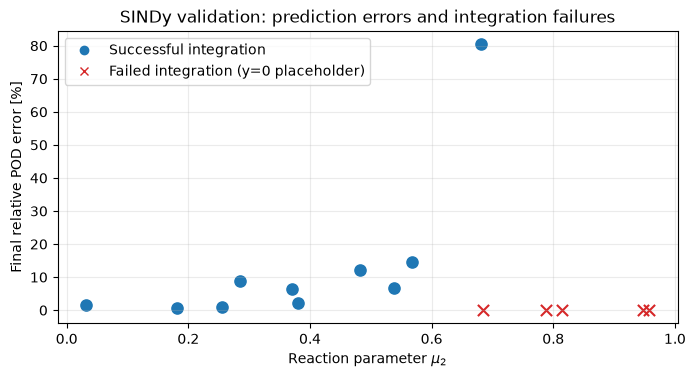

In [11]:
# Validate each SINDy sparsity threshold through autonomous integration.
# Evaluate final-time errors and record failed integrations explicitly.

t_extrap = sensor_times[split_idx:]
validation_results = []

for threshold, Xi in sindy_models.items():
    errors = np.full(len(val_idx), np.nan)

    for k, idx in enumerate(val_idx):
        observed = A_fom[idx, :split_idx + 1, :n_sindy]
        reference = A_fom[idx, split_idx + 1:, :n_sindy]

        # Detect clearly divergent trajectories without using future states
        observed_scale = max(
            np.linalg.norm(observed, axis=1).max(), 1e-12
        )

        prediction = ef.simulate_sindy(
            z0=observed[-1],
            mu=mu_fom[idx],
            Xi=Xi,
            t_eval=t_extrap,
            pairs=quadratic_pairs,
            max_norm=10 * observed_scale
        )

        if prediction is not None:
            errors[k] = 100 * ef.relative_coefficient_errors(
                reference, prediction[1:]
            )[-1]

    successful = np.isfinite(errors)

    validation_results.append({
        "threshold": threshold,
        "success": int(successful.sum()),
        "total": len(val_idx),
        "median_error": (
            np.median(errors[successful]) if successful.any() else np.nan
        ),
        "mean_error": (
            np.mean(errors[successful]) if successful.any() else np.nan
        )
    })

print(f"{'Threshold':>10} {'Success':>10} "
      f"{'Median [%]':>14} {'Mean [%]':>12}")

for result in validation_results:
    print(
        f"{result['threshold']:10.1f} "
        f"{result['success']:>5}/{result['total']:<4} "
        f"{result['median_error']:14.2f} "
        f"{result['mean_error']:12.2f}"
    )

    
# Identify which parameter configurations cause SINDy integration failures.

threshold = 0.1
Xi = sindy_models[threshold]
records = []

for idx in val_idx:
    observed = A_fom[idx, :split_idx + 1, :n_sindy]
    reference = A_fom[idx, -1, :n_sindy]

    max_norm = 10 * max(
        np.linalg.norm(observed, axis=1).max(), 1e-12
    )

    prediction = ef.simulate_sindy(
        observed[-1], mu_fom[idx], Xi,
        sensor_times[split_idx:],
        quadratic_pairs, max_norm=max_norm
    )

    success = prediction is not None
    error = (
        100 * np.linalg.norm(reference - prediction[-1])
        / max(np.linalg.norm(reference), 1e-12)
        if success else np.nan
    )

    records.append((idx, *mu_fom[idx], success, error))

records = sorted(records, key=lambda x: x[2])

print(f"{'Index':>6} {'mu1':>9} {'mu2':>9} {'mu3':>9} "
      f"{'Success':>9} {'Error [%]':>12}")
for idx, m1, m2, m3, ok, err in records:
    print(f"{idx:6d} {m1:9.3f} {m2:9.3f} {m3:9.3f} "
          f"{str(ok):>9} {err:12.2f}")

fig, ax = plt.subplots(figsize=(8, 3.8))

for idx, m1, m2, m3, ok, err in records:
    ax.scatter(
        m2, err if ok else 0,
        marker="o" if ok else "x",
        color="tab:blue" if ok else "tab:red",
        s=65
    )

ax.set(
    xlabel=r"Reaction parameter $\mu_2$",
    ylabel="Final relative POD error [%]",
    title="SINDy validation: prediction errors and integration failures"
)
ax.grid(alpha=0.25)

from matplotlib.lines import Line2D
ax.legend(handles=[
    Line2D([], [], marker="o", linestyle="", color="tab:blue",
           label="Successful integration"),
    Line2D([], [], marker="x", linestyle="", color="tab:red",
           label="Failed integration (y=0 placeholder)")
])
plt.show()


In [12]:
# Select SINDy regularization and sparsity using validation trajectories.
# Search Ridge regularization and sparsity thresholds using validation rollouts.

tuning_df, Xi_sindy_best, best_config = ef.tune_sindy(
    Theta, Y_sindy, Z, Z_dot, r,
    A_fom, mu_fom, val_idx, sensor_times,
    split_idx, quadratic_pairs,
    n_modes=n_sindy,
    alphas=[1e-4, 1e-2, 1.0, 10.0],
    thresholds=[0.1, 10.0, 25.0],
    save_path="artifacts/sindy_tuning.csv"
)

tuning_df


,alpha,threshold,success,high_success,median_error,mean_error,derivative_error,sparsity
0,0.0100,10.0,11,2,8.166213,23.540741,7.405660,47.413043
1,0.0100,0.1,11,2,8.592893,12.790437,7.359448,0.413043
2,0.0001,0.1,10,1,6.565978,13.441916,4.952254,0.173913
3,0.0001,10.0,10,1,6.841685,13.320367,4.955340,20.086957
4,1.0000,25.0,10,1,38.094197,58.597336,59.792717,78.021739
5,0.0100,25.0,9,0,14.277853,15.475421,11.002732,76.152174
6,1.0000,10.0,9,0,26.062083,33.036113,56.990883,50.065217
7,1.0000,0.1,9,0,29.350210,32.361333,56.835903,0.652174
8,10.0000,10.0,9,0,94.389475,111.138664,180.491957,66.260870
9,10.0000,25.0,9,0,102.640594,160.548548,191.883767,89.586957


### 3.6 Hyperparameter tuning

The search considers $\alpha\in\{10^{-4},10^{-2},1,10\}$ and thresholds $\{0.1,10,25\}$. Selection prioritizes high-reaction completion, then overall completion and conditional prediction accuracy.

The selected configuration, $\alpha=10^{-2}$ and threshold $10$, completes **11/15** validation trajectories, including **2/6** with $\mu_{2}\geq0.65$. Its median final coefficient error is **8.17%** among completed forecasts. The baseline completes 10/15 and 1/6, respectively: robustness improves slightly, but most high-reaction forecasts still fail.

**Model bookkeeping.** The unified benchmark uses `Xi_sindy_best`, with 20 modes, $\alpha=10^{-2}$ and threshold 10. The later full-window study separately selects a 10-mode model with threshold 25; these are distinct fitted models.


### 3.7 Dimension and window sensitivity

Reducing the dimension from 20 to 10 lowers the library size from 230 to 65 features. Completion remains **11/15 overall and 2/6 at high reaction**, with a conditional median final FEM $L^{2}$ error of **8.56%**. This differs from the coefficient metric reported for the initial SINDy study.

With the tuned regularization and threshold, excluding the first three snapshots reduces derivative error from **7.41% to 6.02%**, but lowers completion to **10/15 overall and 1/6 at high reaction**. Excluding five or eight snapshots gives 9/15 completions and no successful high-reaction forecasts. Lower conditional medians in these experiments do not demonstrate improved reliability.

Within the explored configurations, neither reduced dimension nor transient exclusion resolves the integration difficulties. Possible contributors include derivative approximation, imperfect POD closure and unconstrained identified operators. These experiments do not isolate their individual effects.


## 4. Alternative Reduced Dynamics Models

### 4.1 Purpose of the comparisons

We investigate four alternatives to distinguish the effects of operator identification, spatial truncation and temporal propagation:

- **POD-Galerkin:** derives operators directly from the PDE.
- **Hybrid Galerkin/SINDy:** adds a learned correction to the projected dynamics.
- **POD-LSTM:** predicts increments from a short state history and the parameters.
- **Discrete-time SINDy:** identifies an increment map from consecutive snapshots.

The comparisons use the same initial temporal holdout. They test whether these alternatives improve completion and accuracy; no formulation is assumed to preserve the physical bounds automatically.


### 4.2 POD-Galerkin

POD-Galerkin applies the projection framework studied in Assignment 1 to the Fisher–KPP problem. For the mass-orthonormal basis,

$$
\dot a=-DK_{N}a+r\bigl(a-q_{N}(a)\bigr),
$$

where

$$
(K_{N})_{ij}=\int_{\Omega}\nabla\phi_{i}\cdot\nabla\phi_{j}\,dx,
\qquad [q_{N}(a)]_{i}=\sum_{j,k=1}^{N} a_{j}a_{k}
\int_{\Omega}\phi_{i}\phi_{j}\phi_{k}\,dx.
$$

The reduced operators are assembled from the FEM basis, avoiding data-driven coefficient estimation. The system is initialized at $T/2$ and integrated with BDF to $T$. We examine $N\in\{10,20,30,50\}$.

For each dimension, the projection error measures how well the subspace represents the final FOM field; the prediction error additionally reflects the evolved coefficients. Exact assembly does not guarantee positivity, saturation or an accurate closure of the discarded modes. Moreover, a continuous reduced ODE and a time-discrete FOM need not have identical numerical dynamics.


In [13]:
# Assemble the physics-based reduced operators and evaluate POD-Galerkin
# extrapolation for N = 10, 20, 30 and 50 POD modes.

from time import perf_counter

galerkin_modes = [10, 20, 30, 50]
tic = perf_counter()

K_galerkin, C_galerkin = ef.assemble_galerkin_operators(
    Vh, Vn[:, :max(galerkin_modes)]
)

assembly_time = perf_counter() - tic

# Basic FEM operator consistency checks
mass_error = np.linalg.norm(
    Vn[:, :50].T @ (M @ Vn[:, :50]) - np.eye(50)
)
symmetry_error = np.linalg.norm(
    C_galerkin - C_galerkin.transpose(0, 2, 1)
)

print(f"Operator assembly: {assembly_time:.2f} s")
print(f"Mass orthogonality error: {mass_error:.2e}")
print(f"Quadratic tensor symmetry error: {symmetry_error:.2e}")

assert mass_error < 1e-8
assert symmetry_error < 1e-8

galerkin_results = ef.benchmark_galerkin(
    mode_counts=galerkin_modes,
    K_full=K_galerkin,
    C_full=C_galerkin,
    A_fom=A_fom,
    u_fom=u_fom,
    mu_fom=mu_fom,
    indices=val_idx,
    Vn=Vn,
    M=M,
    sensor_times=sensor_times,
    split_idx=split_idx
)

print(f"\n{'N':>4} {'POD [%]':>12} {'Galerkin [%]':>15} "
      f"{'Success':>11} {'High mu2':>10}")

for n, result in galerkin_results.items():
    ok = result["success"]

    pod_error = np.median(result["projection_error"])
    pred_error = (
        np.median(result["prediction_error"][ok])
        if ok.any() else np.nan
    )

    print(
        f"{n:4d} {pod_error:12.2f} {pred_error:15.2f} "
        f"{ok.sum():5d}/{len(ok):<5d} "
        f"{result['high_success']:3d}/{result['high_total']}"
    )


Operator assembly: 1.47 s
Mass orthogonality error: 1.20e-11
Quadratic tensor symmetry error: 1.78e-15

   N      POD [%]    Galerkin [%]     Success   High mu2
  10         6.71            7.97    12/15      3/6
  20         3.27            5.61    13/15      4/6
  30         1.47            3.51    13/15      4/6
  50         0.60            3.95    14/15      5/6


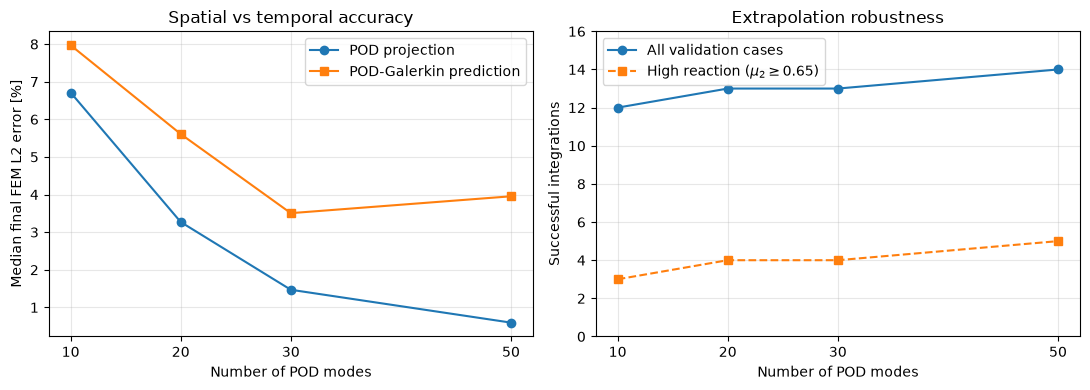

In [14]:
# Compare spatial projection accuracy, temporal prediction accuracy,
# and integration robustness as the POD dimension increases.

modes = np.array(galerkin_modes)

pod_median = [
    np.median(galerkin_results[n]["projection_error"])
    for n in modes
]

galerkin_median = [
    np.nanmedian(galerkin_results[n]["prediction_error"])
    if galerkin_results[n]["success"].any() else np.nan
    for n in modes
]

n_success = [
    galerkin_results[n]["success"].sum()
    for n in modes
]

high_success = [
    galerkin_results[n]["high_success"]
    for n in modes
]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Final-time FEM L2 accuracy
axes[0].plot(
    modes, pod_median, "o-",
    label="POD projection"
)
axes[0].plot(
    modes, galerkin_median, "s-",
    label="POD-Galerkin prediction"
)
axes[0].set(
    xlabel="Number of POD modes",
    ylabel="Median final FEM L2 error [%]",
    title="Spatial vs temporal accuracy"
)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Successful integrations
axes[1].plot(
    modes, n_success, "o-",
    label="All validation cases"
)
axes[1].plot(
    modes, high_success, "s--",
    label=r"High reaction ($\mu_2 \geq 0.65$)"
)
axes[1].set(
    xlabel="Number of POD modes",
    ylabel="Successful integrations",
    title="Extrapolation robustness"
)
axes[1].set_ylim(0, len(val_idx) + 1)
axes[1].legend()
axes[1].grid(alpha=0.3)

for ax in axes:
    ax.set_xticks(modes)

fig.tight_layout()
plt.show()


In [15]:
# Compare POD-Galerkin accuracy on common successful cases and
# evaluate robustness and prediction errors in the high-reaction regime.

common_success = np.logical_and.reduce([
    galerkin_results[n]["success"] for n in galerkin_modes
])

high_reaction = mu_fom[val_idx, 1] >= 0.65

print(f"Common successful trajectories: {common_success.sum()}/{len(val_idx)}")
print(
    f"{'N':>4} {'POD [%]':>10} {'Galerkin [%]':>14} "
    f"{'Success':>10} {'High success':>14} {'High error [%]':>16}"
)

for n in galerkin_modes:
    result = galerkin_results[n]
    success = result["success"]
    high_valid = success & high_reaction

    pod_err = np.median(
        result["projection_error"][common_success]
    )
    gal_err = np.median(
        result["prediction_error"][common_success]
    )
    high_err = (
        np.median(result["prediction_error"][high_valid])
        if high_valid.any() else np.nan
    )

    print(
        f"{n:4d} {pod_err:10.2f} {gal_err:14.2f} "
        f"{success.sum():4d}/{len(success):<5d} "
        f"{high_valid.sum():5d}/{high_reaction.sum():<8d} "
        f"{high_err:16.2f}"
    )


Common successful trajectories: 12/15
   N    POD [%]   Galerkin [%]    Success   High success   High error [%]
  10       5.76           7.97   12/15        3/6                   45.46
  20       3.19           5.34   13/15        4/6                   30.91
  30       1.47           3.50   13/15        4/6                   16.09
  50       0.56           2.97   14/15        5/6                   13.11


### 4.2.1 Results and discussion

For a consistent comparison across dimensions, the first two error columns below use the **12 validation trajectories completed by every Galerkin configuration**. Completion counts use all 15 cases, and high-reaction medians use the successful high-reaction subset of each configuration.

| POD modes | POD projection [%] | Galerkin prediction [%] | Completed | High-reaction completed | High-reaction error [%] |
|---|---:|---:|---|---|---:|
| 10 | 5.76 | 7.97 | 12/15 | 3/6 | 45.46 |
| 20 | 3.19 | 5.34 | 13/15 | 4/6 | 30.91 |
| 30 | 1.47 | 3.50 | 13/15 | 4/6 | 16.09 |
| 50 | 0.56 | 2.97 | 14/15 | 5/6 | 13.11 |

Errors are median final-time FEM $L^{2}$ percentages. High reaction means $\mu_{2}\geq0.65$; those error medians involve different successful subsets.

On the common subset, increasing $N$ improves both projection and prediction accuracy. Completion also improves, but the 50-mode model still fails on one validation trajectory. At $N=20$, Galerkin completes 13/15 overall and 4/6 high-reaction cases, versus 11/15 and 2/6 for tuned continuous SINDy.

The improvement is consistent with a benefit from known operators. It does not isolate identification error from other contributors: both methods remain affected by reduction and numerical propagation.


### 4.3 Hybrid POD-Galerkin/SINDy

We retain the Galerkin nonlinear operator and identify a parameter-scaled linear correction:

$$
\dot a=f_{\mathrm{PG}}(a,\mu)+\lambda(DB_{D}a+rB_{r}a),
\qquad f_{\mathrm{PG}}=-DK_{N}a+r(a-q_{N}(a)).
$$

The matrices $B_{D},B_{r}$ are fitted by regularized regression to the difference between finite-difference derivatives of FOM-projected coefficients and the Galerkin RHS. We use 50 modes and test $\lambda\in\{0,0.01,0.03,0.1,0.3,1\}$ on the validation set.

This residual may include unresolved-mode effects, derivative error and discrepancies due to time discretization. The correction is therefore an empirical adjustment, rather than a separately identified physical mechanism.


In [16]:
# Fit a physics-based hybrid correction and assess whether it improves
# POD-Galerkin extrapolation accuracy and robustness.

N_hybrid = 50
alpha_hybrid = 1e-3
lambda_values = [0.0, 0.01, 0.03, 0.1, 0.3, 1.0]

K_h = K_galerkin[:N_hybrid, :N_hybrid]
C_h = C_galerkin[:N_hybrid, :N_hybrid, :N_hybrid]

B_D, B_r, hybrid_fit = ef.fit_hybrid_correction(
    A_fom[train_idx, :split_idx + 1, :N_hybrid],
    mu_fom[train_idx],
    K_h, C_h, dt, alpha=alpha_hybrid
)

print("Training derivative errors:")
print(f"  POD-Galerkin: {hybrid_fit['galerkin_derivative_error']:.2f}%")
print(f"  Hybrid:      {hybrid_fit['hybrid_derivative_error']:.2f}%")

hybrid_results = {}
high_mu2 = mu_fom[val_idx, 1] >= 0.65

for lam in lambda_values:
    errors = np.full(len(val_idx), np.nan)

    for j, idx in enumerate(val_idx):
        observed = A_fom[idx, :split_idx + 1, :N_hybrid]
        scale = max(np.linalg.norm(observed, axis=1).max(), 1e-12)

        pred = ef.simulate_hybrid(
            observed[-1], mu_fom[idx],
            K_h, C_h, B_D, B_r,
            sensor_times[split_idx:],
            correction_strength=lam,
            divergence_limit=10 * scale
        )

        if pred is not None:
            u_pred = sf.reconstruct_pod(pred[-1], Vn[:, :N_hybrid])
            errors[j] = 100 * sf.relative_l2_error(
                u_fom[idx, -1:],
                u_pred[None, :], M
            )[0]

    success = np.isfinite(errors)

    hybrid_results[lam] = {
        "errors": errors,
        "success": success,
        "high_success": int((success & high_mu2).sum()),
        "median": np.median(errors[success]) if success.any() else np.nan,
        "penalized_mean": np.mean(np.where(success, errors, 200.0))
    }

print(f"\n{'Lambda':>8} {'Success':>10} {'High mu2':>10} "
      f"{'Median [%]':>13} {'Penalized [%]':>15}")

for lam, res in hybrid_results.items():
    print(
        f"{lam:8.2f} "
        f"{res['success'].sum():5d}/{len(val_idx):<4d} "
        f"{res['high_success']:5d}/{high_mu2.sum():<4d} "
        f"{res['median']:13.2f} "
        f"{res['penalized_mean']:15.2f}"
    )

best_lambda = min(
    lambda_values,
    key=lambda lam: (
        -hybrid_results[lam]["high_success"],
        -hybrid_results[lam]["success"].sum(),
        hybrid_results[lam]["penalized_mean"]
    )
)
print(f"\nSelected correction strength: lambda = {best_lambda:g}")


Training derivative errors:
  POD-Galerkin: 176.80%
  Hybrid:      12.65%

  Lambda    Success   High mu2    Median [%]   Penalized [%]
    0.00    14/15       5/6             3.95           24.02
    0.01    14/15       5/6             3.85           23.83
    0.03    14/15       5/6             3.63           23.66
    0.10    14/15       5/6             2.90           24.48
    0.30    14/15       5/6             1.48           42.29
    1.00    14/15       5/6             5.48           22.77

Selected correction strength: lambda = 1


In [17]:
# Compare hybrid correction strengths on the high-reaction validation cases.
# Highlight potential improvements and extreme errors without rerunning models.

high_mu2 = mu_fom[val_idx, 1] >= 0.65

print(f"{'Lambda':>8} {'High success':>14} "
      f"{'High median [%]':>17} {'High max [%]':>15}")

for lam, res in hybrid_results.items():
    errors = res["errors"]
    valid_high = np.isfinite(errors) & high_mu2

    median_high = (
        np.median(errors[valid_high]) if valid_high.any() else np.nan
    )
    max_high = (
        np.max(errors[valid_high]) if valid_high.any() else np.nan
    )

    print(
        f"{lam:8.2f} "
        f"{valid_high.sum():5d}/{high_mu2.sum():<8d} "
        f"{median_high:17.2f} "
        f"{max_high:15.2f}"
    )


  Lambda   High success   High median [%]    High max [%]
    0.00     5/6                    13.11           90.22
    0.01     5/6                    13.05           88.78
    0.03     5/6                    12.92           88.76
    0.10     5/6                    12.38          109.85
    0.30     5/6                     7.93          395.00
    1.00     5/6                    11.42           56.47


### 4.3.1 Results and discussion

The correction reduces the training derivative discrepancy from **176.80% to 12.65%**, but this does not translate into uniformly better forecasts. The large original discrepancy alone does not establish an error in the Galerkin operators: the derivative estimate and projected continuous RHS are different numerical quantities, particularly during the initial transient.

All tested strengths complete **14/15** trajectories, including **5/6** at high reaction. At $\lambda=0.3$, the high-reaction median improves from **13.11% to 7.93%**, while the maximum worsens from **90.22% to 395.00%**. At $\lambda=1$, the high-reaction maximum falls to **56.47%**, but global accuracy does not improve consistently.

The implementation selects $\lambda=1$ using completion counts followed by a penalized mean, assigning 200% to failed cases. This penalty is an exploratory selection rule, not a measured error for a failed forecast. The later unified benchmark reports failures without such a penalty.

Pure Galerkin is retained in that benchmark as the simpler reference, because the correction does not improve completion and its accuracy benefits depend on the trajectory and strength.


### 4.4 POD-LSTM

A parameter-conditioned LSTM predicts the next POD state through an increment:

$$
\widehat a_{k+1}=a_{k}+
F_{\theta}(a_{k-p+1},\ldots,a_{k},\mu).
$$

Training uses FOM-projected histories and one-step mean squared error on standardized coefficients, optionally weighting high-reaction trajectories. During prediction, the network receives its own previous outputs. Checkpoints are selected by validation error after the entire autonomous rollout, rather than training loss alone.

The model avoids derivative estimation and ODE integration, but its one-step objective does not directly penalize accumulated rollout error or enforce $0\leq u\leq1$.


In [18]:
# Train or reload the selected POD-LSTM, cache its checkpoint,
# and evaluate full-rollout extrapolation on the validation set.

device = "cuda" if torch.cuda.is_available() else "cpu"

lstm_config = {
    "n_modes": 10,
    "seq_len": 5,
    "hidden_size": 128,
    "weight_strength": best_lstm_weight,
    "seed": 42,
}

checkpoint_path = Path("artifacts/pod_lstm_best.pt")
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

if checkpoint_path.exists():
    # Reload the previously selected model without retraining.
    checkpoint = torch.load(
        checkpoint_path, map_location=device, weights_only=False
    )

    lstm_config = checkpoint["config"]
    lstm_scaling = checkpoint["scaling"]

    best_lstm = ef.ParametricPODLSTM.build(
        n_modes=lstm_config["n_modes"],
        hidden_size=lstm_config["hidden_size"]
    ).to(device)

    best_lstm.load_state_dict(checkpoint["state_dict"])
    best_lstm.eval()

    print("POD-LSTM checkpoint loaded.")

else:
    # Fit the selected configuration using observed training snapshots.
    A_scaled, mu_scaled, lstm_scaling = ef.prepare_pod_lstm_data(
        A_fom, mu_fom, train_idx, split_idx,
        n_modes=lstm_config["n_modes"]
    )

    best_lstm, lstm_history, lstm_info = ef.train_pod_lstm(
        A_scaled, mu_scaled, mu_fom,
        lstm_scaling, train_idx, val_idx, split_idx,
        Vn, M, u_fom,
        seq_len=lstm_config["seq_len"],
        hidden_size=lstm_config["hidden_size"],
        weight_strength=lstm_config["weight_strength"],
        seed=lstm_config["seed"],
        device=device,
        epochs =500
    )

    torch.save({
        "state_dict": best_lstm.state_dict(),
        "config": lstm_config,
        "scaling": lstm_scaling,
        "best_epoch": lstm_info["best_epoch"]
    }, checkpoint_path)

    print(
        f"POD-LSTM trained and saved "
        f"(best epoch: {lstm_info['best_epoch']})."
    )

# Evaluate final-time FEM L2 error after autoregressive rollout.
lstm_val = ef.evaluate_pod_lstm(
    best_lstm, A_fom, mu_fom, val_idx,
    split_idx, lstm_config["seq_len"],
    lstm_scaling, Vn, M, u_fom,
    device=device
)

high = lstm_val["high_mask"]
errors = lstm_val["errors"]
success = lstm_val["success"]

print(f"\nOverall median error: {lstm_val['median']:.2f}%")
print(f"High-reaction median: {lstm_val['high_median']:.2f}%")
print(f"High-reaction max:    {np.nanmax(errors[high]):.2f}%")
print(f"Successful rollouts: {success.sum()}/{len(success)}")
print(f"Checkpoint: {checkpoint_path}")


POD-LSTM checkpoint loaded.

Overall median error: 10.98%
High-reaction median: 18.67%
High-reaction max:    33.13%
Successful rollouts: 15/15
Checkpoint: artifacts/pod_lstm_best.pt


### 4.4.1 Hyperparameter selection and results

The exploratory study considered dimensions $N\in\{10,20,30,50\}$, histories $p\in\{3,5,8\}$, hidden sizes $h\in\{32,64,128\}$, and uniform or high-reaction-weighted loss. These were staged comparisons, not a full Cartesian search.

Training is restricted to $[0,T/2]$. Early stopping and checkpoint selection use the high-reaction median final FEM $L^{2}$ validation error after rollout to $T$.

With fixed $p=5,h=64$, increasing dimension does not systematically improve accuracy: the overall median ranges from 14.46% at $N=10$ to 22.88% at $N=50$. Longer history is not consistently beneficial. A larger hidden size improves the 10-mode model.

The saved selected configuration has **10 modes, history 5, hidden size 128 and high-reaction weight strength 4.0**; the training multiplier is therefore 5 for high-reaction trajectories and 1 otherwise.

| Validation metric | POD-LSTM |
|---|---:|
| Completed rollouts | 15/15 |
| High-reaction completed | 6/6 |
| Overall median FEM L² [%] | 10.98 |
| High-reaction median [%] | 18.67 |
| High-reaction maximum [%] | 33.13 |

The model completes all validation forecasts, but completion alone establishes neither physical admissibility nor accuracy beyond the evaluated horizon.


### 4.5 Discrete-Time Parametric SINDy

This alternative learns a state increment from consecutive snapshot pairs:

$$
z_{k+1}=z_{k}+\Theta(z_{k},p)\Xi,
$$

where $z$ and $p$ are standardized POD coefficients and parameters. The library includes a constant, linear and quadratic state terms, linear parameter terms, and parameter–state products. Ridge/STLSQ acts on feature columns normalized by their RMS.

Identification uses training pairs within $[0,T/2]$; validation iterates the map autonomously to $T$. This avoids numerical derivatives and continuous-time integration, but the learned map depends on the sampling step and may accumulate error or violate physical bounds under iteration.


In [19]:
# Fit or reload the validation-selected discrete-time SINDy model,
# then evaluate its autonomous forecast over [T/2, T].

from pathlib import Path
import numpy as np

discrete_config = {
    "n_modes": 5,
    "alpha": 1.0,
    "threshold": 0.01,
}

checkpoint_path = Path("artifacts/discrete_sindy_best.npz")
checkpoint_path.parent.mkdir(parents=True, exist_ok=True)

if checkpoint_path.exists():
    data = np.load(checkpoint_path)

    discrete_best = {
        key: data[key].item() if data[key].ndim == 0 else data[key]
        for key in data.files
    }

    assert discrete_best["rank"] == discrete_config["n_modes"]
    assert np.isclose(discrete_best["alpha"], discrete_config["alpha"])
    assert np.isclose(discrete_best["threshold"], discrete_config["threshold"])

    print("Discrete-time SINDy checkpoint loaded.")

else:
    discrete_best = ef.fit_discrete_sindy(
        A_fom[
            train_idx,
            :split_idx + 1,
            :discrete_config["n_modes"]
        ],
        mu_fom[train_idx],
        alpha=discrete_config["alpha"],
        threshold=discrete_config["threshold"]
    )

    np.savez_compressed(checkpoint_path, **discrete_best)
    print("Discrete-time SINDy trained and saved.")

discrete_val = ef.evaluate_discrete_sindy(
    discrete_best, A_fom, mu_fom,
    val_idx, split_idx, Vn, M, u_fom
)

print(f"Completed: {discrete_val['success'].sum()}/{len(val_idx)}")
print(f"Overall median: {discrete_val['median']:.2f}%")
print(f"High-reaction median: {discrete_val['high_median']:.2f}%")
print(f"High-reaction maximum: {discrete_val['high_max']:.2f}%")


Discrete-time SINDy checkpoint loaded.


Completed: 15/15
Overall median: 28.19%
High-reaction median: 28.69%
High-reaction maximum: 31.47%


### 4.5.1 Hyperparameter selection and results

The exploratory search considered $N\in\{5,8,10\}$ and $\alpha\in\{10^{-2},1,10^{2}\}$ with threshold $0.01$, prioritizing completion and final FEM $L^{2}$ accuracy.

The saved selected configuration is $N=5$, $\alpha=1$, threshold $0.01$, with 65 active coefficients.

| Validation metric | Discrete SINDy |
|---|---:|
| Completed rollouts | 15/15 |
| High-reaction completed | 6/6 |
| Overall median FEM L² [%] | 28.19 |
| High-reaction median [%] | 28.69 |
| High-reaction maximum [%] | 31.47 |

Weak regularization can produce divergent or inaccurate iterates, while stronger regularization trades flexibility for robustness. Here discrete SINDy completes as many validation forecasts as LSTM, but with larger median errors. Its feature-based evolution law is inspectable; its usefulness still depends on the forecast quality.


**Spatial representation versus evolution error.**

| POD modes | POD projection [%] | Discrete SINDy [%] | Completed |
|---|---:|---:|---|
| 5 | 13.12 | 28.19 | 15/15 |
| 8 | 8.68 | 33.86 | 15/15 |
| 10 | 6.71 | 37.19 | 13/15 |

Entries are median final-time FEM $L^{2}$ percentages. Projection medians use the validation set; forecast medians exclude failures, so the last row compares different populations.

More POD modes improve projection but do not improve the tested evolution maps. Thus spatial truncation alone does not explain their errors. This comparison does not prove that the current coordinates are optimal or that a nonlinear representation would be ineffective. An autoencoder was not explored, to keep this study focused on temporal identification and propagation.


## 5. Unified Test-Set Benchmark

### 5.1 Protocol and configurations

The benchmark uses 25 held-out parameter trajectories, with observed history $[0,T/2]$ and forecast horizon $(T/2,T]$. DMD fits its operator to each test prefix with fixed rank and starting index; the learned parametric models reuse training-derived dynamics. Galerkin uses assembled physical operators. This is continuation of partially observed trajectories, rather than prediction from parameters alone.

The configurations actually used by the following code are:

| Model | Benchmark configuration |
|---|---|
| DMD | 50 POD modes; rank 18; starting index 0 |
| Continuous SINDy | 20 modes; $\alpha=10^{-2}$; threshold 10; `Xi_sindy_best` |
| POD-Galerkin | 50 modes; no learned correction |
| POD-LSTM | Saved 10-mode, history-5, hidden-128 model |
| Discrete SINDy | 5 modes; $\alpha=1$; threshold 0.01 |

The continuous-SINDy row uses the configuration selected in Section 3.6. The separate full-window selection in Section 6 uses different configurations.

### 5.2 Metrics and interpretation

For each test trajectory,

$$
E_{i}(t)=100\frac{\|u_{h}(t;\mu_{i})-\widehat u_{i}(t;\mu_{i})\|_{M}}
{\|u_{h}(t;\mu_{i})\|_{M}},\qquad t\in[T/2,T].
$$

We report final-time median, mean, P90 and high-reaction statistics, together with completion counts. Error summaries and temporal medians include only completed forecasts; the common-success comparison additionally restricts all methods to the same subset. Neither selection represents the full difficult regime by itself.

The initial state or history is projected into each model's retained POD dimension, so the reconstructed initial fields differ across methods. DMD also propagates in its fitted rank-$r$ subspace. Projection errors are reported separately to characterize spatial approximation.


In [20]:
# Configure the five frozen extrapolation models on the common test horizon.
# No hyperparameter tuning or parameter estimation is performed here,
# except trajectory-specific DMD fitting on the observed test segment.


t_forecast = sensor_times[split_idx:]
n_forecast_steps = len(t_forecast) - 1

benchmark_modes = {
    "DMD": 50,
    "Continuous SINDy": 20,
    "POD-Galerkin": 50,
    "POD-LSTM": 10,
    "Discrete SINDy": 5,
}

def forecast_dmd(idx):
    # DMD rank 18, identified only on the observed segment.
    """Return the DMD coefficient forecast using the enclosing observation window and rank settings."""
    a = A_fom[idx, :, :50]
    _, predicted = ef.dmd_forecast(
        a, rank=18, split_idx=split_idx, start_idx=0
    )
    return np.vstack([a[split_idx], predicted])


def forecast_continuous_sindy(idx):
    # Reuse the trained parametric continuous-time SINDy coefficients.
    """Integrate the trained continuous SINDy model from trajectory idx at the forecast split."""
    return ef.simulate_sindy(
        A_fom[idx, split_idx, :20],
        mu_fom[idx],
        Xi_sindy_best,
        t_forecast,
        quadratic_pairs
    )


def forecast_galerkin(idx):
    # Integrate previously assembled physics-based reduced operators.
    """Integrate the Galerkin ROM from trajectory idx with an observation-based divergence limit."""
    observed = A_fom[idx, :split_idx + 1, :50]
    scale = max(np.linalg.norm(observed, axis=1).max(), 1e-12)

    return ef.simulate_galerkin(
        observed[-1], mu_fom[idx],
        K_galerkin, C_galerkin, t_forecast,
        divergence_limit=10 * scale
    )


def forecast_lstm(idx):
    # Autoregressive rollout from the last five observed POD states.
    """Roll out the trained POD-LSTM from the final observed history of trajectory idx."""
    p = lstm_config["seq_len"]
    n = lstm_config["n_modes"]

    return ef.rollout_pod_lstm(
        best_lstm,
        A_fom[idx, split_idx-p+1:split_idx+1, :n],
        mu_fom[idx],
        lstm_scaling,
        n_forecast_steps,
        device=device
    )


def forecast_discrete_sindy(idx):
    # Polynomial autoregressive rollout from the observed final state.
    """Iterate the trained discrete SINDy map from trajectory idx at the forecast split."""
    n = discrete_best["rank"]

    return ef.rollout_discrete_sindy(
        discrete_best,
        A_fom[idx, split_idx, :n],
        mu_fom[idx],
        n_forecast_steps
    )


forecasters = {
    "DMD": forecast_dmd,
    "Continuous SINDy": forecast_continuous_sindy,
    "POD-Galerkin": forecast_galerkin,
    "POD-LSTM": forecast_lstm,
    "Discrete SINDy": forecast_discrete_sindy,
}


In [21]:
# Evaluate all selected models on the independent test set.
# Report FEM L2 accuracy, rollout completion and high-reaction performance.

import pandas as pd
import support_functions as sf

test_results = ef.benchmark_temporal_models(
    forecasters=forecasters,
    A_fom=A_fom,
    u_fom=u_fom,
    mu_fom=mu_fom,
    test_idx=test_idx,
    Vn=Vn,
    M=M,
    split_idx=split_idx,
    mode_counts=benchmark_modes
)

summary_rows = []

for name, result in test_results.items():
    success = result["success"]
    high = result["high_mask"]
    errors = result["final_errors"]

    valid = errors[success]
    valid_high = errors[success & high]

    summary_rows.append({
        "Model": name,
        "Success": f"{success.sum()}/{len(success)}",
        "High success": f"{(success & high).sum()}/{high.sum()}",
        "Median [%]": np.median(valid) if valid.size else np.nan,
        "Mean [%]": np.mean(valid) if valid.size else np.nan,
        "P90 [%]": np.percentile(valid, 90) if valid.size else np.nan,
        "High median [%]": (
            np.median(valid_high) if valid_high.size else np.nan
        ),
        "High max [%]": (
            np.max(valid_high) if valid_high.size else np.nan
        ),
    })

test_summary = pd.DataFrame(summary_rows)
display(test_summary.round(2))

common_success = np.logical_and.reduce([
    result["success"] for result in test_results.values()
])

print(
    f"\nCommon successful test trajectories: "
    f"{common_success.sum()}/{len(test_idx)}"
)

for name, result in test_results.items():
    common_errors = result["final_errors"][common_success]
    print(
        f"{name:18s} | "
        f"common median = "
        f"{np.median(common_errors):.2f}%"
        if common_errors.size else f"{name}: no common successful cases"
    )

for name, result in test_results.items():
    if result["failures"]:
        print(f"\n{name} failures: {result['failures']}")


,Model,Success,High success,Median [%],Mean [%],P90 [%],High median [%],High max [%]
0,DMD,25/25,8/8,5.70,58.13,146.81,87.19,418.57
1,Continuous SINDy,17/25,1/8,7.50,53.59,60.39,121.55,121.55
2,POD-Galerkin,23/25,6/8,3.99,11.65,17.13,14.35,143.51
3,POD-LSTM,25/25,8/8,10.77,19.83,43.54,30.03,57.75
4,Discrete SINDy,25/25,8/8,29.90,29.57,34.65,30.45,35.44



Common successful test trajectories: 17/25
DMD                | common median = 0.84%
Continuous SINDy   | common median = 7.50%
POD-Galerkin       | common median = 2.16%
POD-LSTM           | common median = 9.87%
Discrete SINDy     | common median = 28.21%

Continuous SINDy failures: {47: 'Incomplete or failed rollout', 0: 'Incomplete or failed rollout', 5: 'Incomplete or failed rollout', 48: 'Incomplete or failed rollout', 42: 'Incomplete or failed rollout', 3: 'Incomplete or failed rollout', 46: 'Incomplete or failed rollout', 67: 'Incomplete or failed rollout'}

POD-Galerkin failures: {47: 'Incomplete or failed rollout', 42: 'Incomplete or failed rollout'}


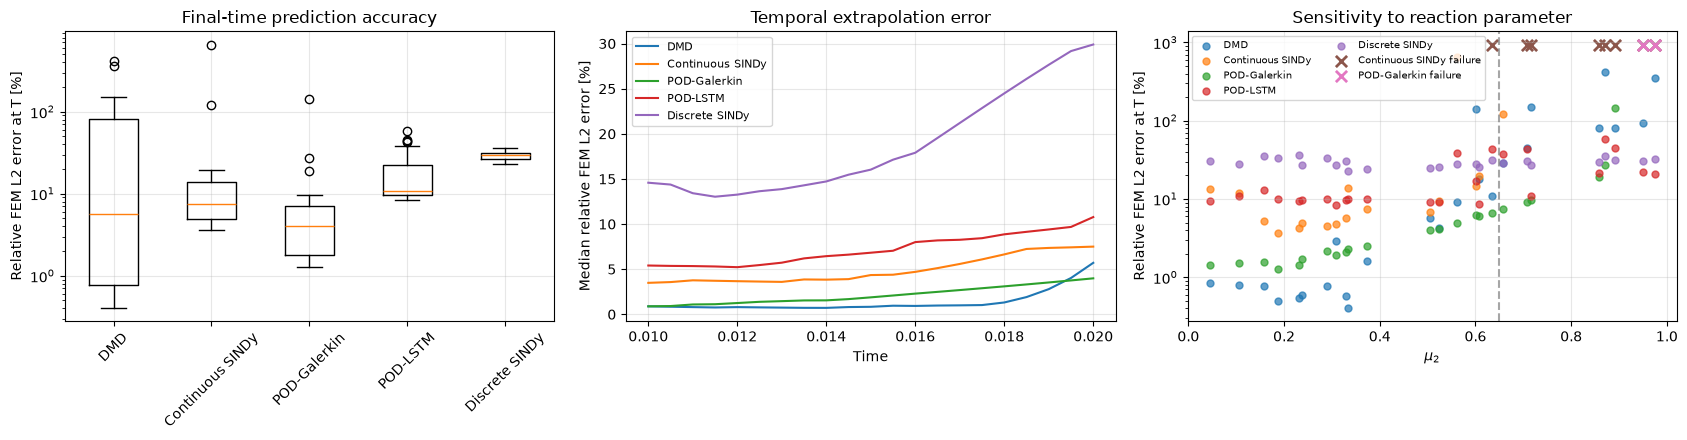

In [22]:
# Visualize final-time error distributions, temporal error growth,
# and sensitivity to the reaction parameter on the test set.

names = list(test_results)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# A. Final-time error distributions
data = [
    test_results[name]["final_errors"][test_results[name]["success"]]
    for name in names
]

axes[0].boxplot(
    data, tick_labels=names, showfliers=True
)
axes[0].set_yscale("log")
axes[0].set(
    title="Final-time prediction accuracy",
    ylabel="Relative FEM L2 error at T [%]"
)
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(alpha=0.3)

# B. Median error evolution across complete test rollouts
for name in names:
    result = test_results[name]
    complete_errors = result["errors"][result["success"]]

    if len(complete_errors) == 0:
        continue

    median = np.median(complete_errors, axis=0)
    axes[1].plot(t_forecast, median, label=name)

axes[1].set(
    title="Temporal extrapolation error",
    xlabel="Time",
    ylabel="Median relative FEM L2 error [%]"
)
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)

# C. Error dependence on the reaction parameter
mu2_test = mu_fom[test_idx, 1]

for name in names:
    result = test_results[name]
    ok = result["success"]

    axes[2].scatter(
        mu2_test[ok],
        result["final_errors"][ok],
        s=25,
        alpha=0.7,
        label=name
    )

axes[2].axvline(
    0.65, linestyle="--", color="gray", alpha=0.7
)
axes[2].set(
    title="Sensitivity to reaction parameter",
    xlabel=r"$\mu_2$",
    ylabel="Relative FEM L2 error at T [%]"
)
axes[2].set_yscale("log")
axes[2].grid(alpha=0.3)

# Mark failed trajectories in the reaction-parameter plot.
# Marker height is illustrative and does not represent a numerical error.

ax = axes[2]

failure_level = max(
    np.nanmax(r["final_errors"])
    for r in test_results.values()
    if np.any(np.isfinite(r["final_errors"]))
) * 1.4

for name in names:
    result = test_results[name]
    failed = ~result["success"]

    if failed.any():
        ax.scatter(
            mu2_test[failed],
            np.full(failed.sum(), failure_level),
            marker="x",
            s=65,
            linewidths=2,
            label=f"{name} failure"
        )

ax.set_ylim(top=failure_level * 1.5)
ax.legend(fontsize=7, ncol=2)
fig

fig.tight_layout()
plt.show()


### 5.3 Test-set results

| Model | Completed | High-reaction completed | Median FEM L² [%] | P90 [%] | High-reaction median [%] |
|---|---|---|---:|---:|---:|
| DMD | 25/25 | 8/8 | 5.70 | 146.81 | 87.19 |
| Continuous SINDy (validation-selected) | 17/25 | 1/8 | 7.50 | 60.39 | 121.55 |
| POD-Galerkin | 23/25 | 6/8 | 3.99 | 17.13 | 14.35 |
| POD-LSTM | 25/25 | 8/8 | 10.77 | 43.54 | 30.03 |
| Discrete SINDy | 25/25 | 8/8 | 29.90 | 34.65 | 30.45 |

Errors are measured at $T$ and conditioned on completed forecasts. High reaction means $\mu_{2}\geq0.65$.

Galerkin has the lowest overall conditional median and P90, but fails on two high-reaction cases and has some large errors among completed forecasts. DMD has a low global median yet a high-reaction median of 87.19%; its 0.84% median on the 17 common successful cases describes a favorable subset. Continuous SINDy fails on seven of eight high-reaction cases; the sole completed high-reaction forecast has 121.55% error. Validation-based selection therefore does not establish robustness on independent high-reaction test trajectories.

LSTM and discrete SINDy complete all cases. LSTM has the lower global median, while discrete SINDy has a narrower distribution of larger errors. Numerical completion is distinct from physical admissibility.

The temporal median curves summarize completed trajectories. Their initial discrepancy reflects spatial projection, while subsequent behavior also includes propagation errors. The initial holdout identifies useful forecasts for some trajectories, but no method demonstrates uniformly accurate continuation in the high-reaction regime.


### 5.4 Illustrative pointwise trajectories

The displayed trajectories are selected among cases completed by all five models. Their reaction parameters are $\mu_{2}=0.373$ and $0.658$, representing moderate and higher reaction, respectively. The second is less reactive than the final target, $\mu_{\mathrm{opt},2}\approx0.897$; these examples therefore do not cover the most difficult cases excluded by completion-based selection.

Both are evaluated at $x_{\mathrm{damage}}\approx(2.759,4.712)$, chosen to show nontrivial damage evolution. This diagnostic point differs from the final target $x^{\ast}=(3.5,2)$.

The plots compare local evolution and the transition from observed history to autonomous prediction. Model-specific projection means exact initial pointwise agreement with the FOM is not expected. These are illustrative trajectories, not an additional model-selection procedure or a substitute for the full test-set statistics.


High reaction: idx=42, mu=[0.37454012 0.95071431 0.73199394], u(x_damage,T)=0.9996
Lower reaction: idx=36, mu=[0.72850719 0.60161421 0.95218067], u(x_damage,T)=0.9564
Moderate reaction: idx=32, mu=[0.85888927 0.37271115 0.55512878]
High reaction: idx=93, mu=[0.60635434 0.65751157 0.30724101]


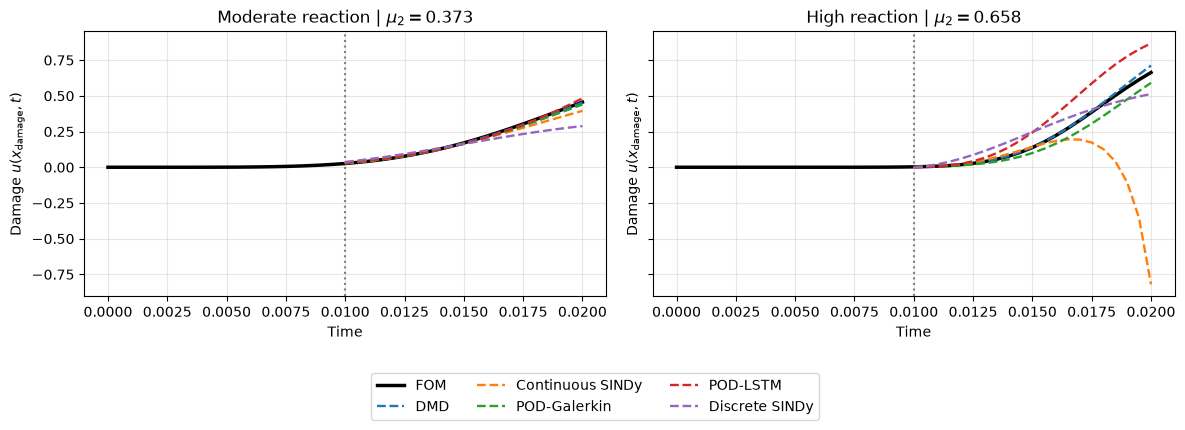

In [23]:
# Select two representative test trajectories at x_damage:
# one high-reaction case and one lower-reaction but still informative case.

damage_point = (2.75866689, 4.71215822)

def final_damage_at_point(idx, point):
    """Return the final available FOM damage for trajectory idx at the requested point."""
    return evaluate_fem_at_point(u_fom[idx, -1], point)

test_idx_array = np.asarray(test_idx)

mu2_test = mu_fom[test_idx_array, 1]
damage_final = np.array([
    final_damage_at_point(idx, damage_point) for idx in test_idx_array
])

high_mask = mu2_test >= 0.65
low_mask = mu2_test < 0.65

# High-reaction case: among high-mu2 trajectories, pick the one with largest final damage
high_candidates = test_idx_array[high_mask]
high_damage = damage_final[high_mask]
idx_high = int(high_candidates[np.argmax(high_damage)])

# Lower-reaction informative case: among low-mu2 trajectories, pick the one with largest final damage
low_candidates = test_idx_array[low_mask]
low_damage = damage_final[low_mask]
idx_low = int(low_candidates[np.argmax(low_damage)])

trajectory_cases = {
    "High reaction": idx_high,
    "Lower reaction": idx_low,
}

for name, idx in trajectory_cases.items():
    print(
        f"{name}: idx={idx}, "
        f"mu={mu_fom[idx]}, "
        f"u(x_damage,T)={final_damage_at_point(idx, damage_point):.4f}"
    )
    # Select two representative test trajectories among the cases
# successfully completed by all models:
# one with mu2 close to 0.4 and one with mu2 close to 0.9.

common_success = np.logical_and.reduce([
    result["success"] for result in test_results.values()
])

common_indices = np.asarray(test_idx)[common_success]
common_mu2 = mu_fom[common_indices, 1]

targets = {
    "Moderate reaction": 0.40,
    "High reaction": 0.90,
}

selected_cases = {}
used = set()

for label, target in targets.items():
    order = np.argsort(np.abs(common_mu2 - target))
    for pos in order:
        idx = int(common_indices[pos])
        if idx not in used:
            selected_cases[label] = idx
            used.add(idx)
            break

for label, idx in selected_cases.items():
    print(f"{label}: idx={idx}, mu={mu_fom[idx]}")
    # Compare local damage evolution at a damage-sensitive point
# for two representative test trajectories completed by all models.

damage_point = (2.75866689, 4.71215822)
forecast_times = np.asarray(sensor_times[split_idx:])

# Reuse the helper function already defined earlier:
# evaluate_fem_at_point(field, point)

# Precompute POD mode values at the selected point
damage_mode_values = np.array([
    evaluate_fem_at_point(Vn[:, j], damage_point)
    for j in range(Vn.shape[1])
])

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, (case_name, idx) in zip(axes, selected_cases.items()):

    # FOM reference over the full time interval
    u_reference = np.array([
        evaluate_fem_at_point(field, damage_point)
        for field in u_fom[idx]
    ])

    ax.plot(
        sensor_times, u_reference,
        color="black", linewidth=2.5, label="FOM"
    )

    # Plot all ROM forecasts (all should be available by construction)
    for name, result in test_results.items():
        coefficients = result["forecasts"].get(int(idx))

        if coefficients is None:
            continue

        n = coefficients.shape[1]
        u_pred = coefficients @ damage_mode_values[:n]

        ax.plot(
            forecast_times, u_pred,
            "--", linewidth=1.7, label=name
        )

    ax.axvline(
        sensor_times[split_idx],
        color="gray", linestyle=":", linewidth=1.5
    )

    ax.set(
        title=f"{case_name} | " + rf"$\mu_2={mu_fom[idx, 1]:.3f}$",
        xlabel="Time",
        ylabel=r"Damage $u(x_{\mathrm{damage}}, t)$"
    )
    ax.grid(alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.08),
    ncol=3
)

fig.tight_layout(rect=[0, 0.1, 1, 1])
plt.show()


## 6. Final Damage Extrapolation at $2T$

### 6.1 History reconstruction and full-window identification

At the parameters inferred in Problem III, the POD-NN reconstructs $\widehat a_{\mathrm{NN}}(t;\mu_{\mathrm{opt}})$ over $[0,T]$. The temporal models then propagate from $T$ to $2T$ and evaluate

$$
\widehat u(x^{\ast},2T)=\sum_{j=1}^{n}\widehat a_{j}(2T)\phi_{j}(x^{\ast}),
$$

with $n$ appropriate to each method. The POD-NN is queried only within its training time range.

For this final forecast, continuous/discrete SINDy and LSTM are identified on complete **training** trajectories up to $T$, preserving the parameter split. DMD is fitted to the full POD-NN history at the target parameters; Galerkin operators remain unchanged.

This changes the interpretation of the intermediate comparison: full-window models evaluated from $T/2$ to $T$ at unseen parameters perform an autonomous rollout **within the temporal range represented in training**, not beyond it. The initial benchmark restricted temporal identification to $T/2$; the final prediction extends beyond the maximum available time.

The final rollout is 40 steps rather than the initial benchmark's 20, and its seed is a surrogate prediction. Parameter-estimation error, reconstruction error and propagation error may all affect the result.


In [24]:
# Final full-window tuning: train missing configurations, reuse cached
# checkpoints, and save the selected models for extrapolation to 2T.

final_tuning = ef.run_final_full_window_tuning(
    A_fom=A_fom,
    u_fom=u_fom,
    mu_fom=mu_fom,
    train_idx=train_idx,
    val_idx=val_idx,
    Vn=Vn,
    M=M,
    time_grid=sensor_times,
    split_idx=split_idx,
    cache_dir="artifacts/final_dynamics",
    max_epochs=350,
    eval_every=25,
    seed=42,
    device="cuda" if torch.cuda.is_available() else "cpu",
)

display(
    final_tuning["results"]
    .sort_values(
        ["Model", "High success", "Success", "High median [%]"],
        ascending=[True, False, False, True]
    )
    .groupby("Model")
    .head(5)
    .round(3)
)
clear_output()

### 6.2 Full-window model selection

The search reconsiders dimensions and regularization for SINDy, and dimension, history, hidden size, weighting and learning rate for LSTM. LSTM candidates train for up to 350 epochs, with checkpoints evaluated every 25 epochs. Selection uses validation trajectories and prioritizes high-reaction completion and accuracy; candidates and selected models are cached.

DMD is tuned separately through trajectory-specific fits, prioritizing the longer available holdout from $T/2$ to $T$. Its selected rank and starting index are then used when fitting the target history through $T$.

| Model | Selected configuration for the final forecast |
|---|---|
| DMD | Rank 10; fitting start index 5 |
| Continuous SINDy | $n=10$, $\alpha=0.01$, threshold 25 |
| Discrete SINDy | $n=10$, $\alpha=10$, threshold 0.001 |
| POD-LSTM | $n=20$, history 5, hidden size 128, learning rate $10^{-3}$, unweighted loss |
| POD-Galerkin | 50 modes; unchanged operators |

These are different from the initial benchmark configurations. The following two-case comparison illustrates the effect of full-window training, but cannot validate the subsequent $T\to2T$ forecast.


Selected LSTM checkpoint epoch: 300


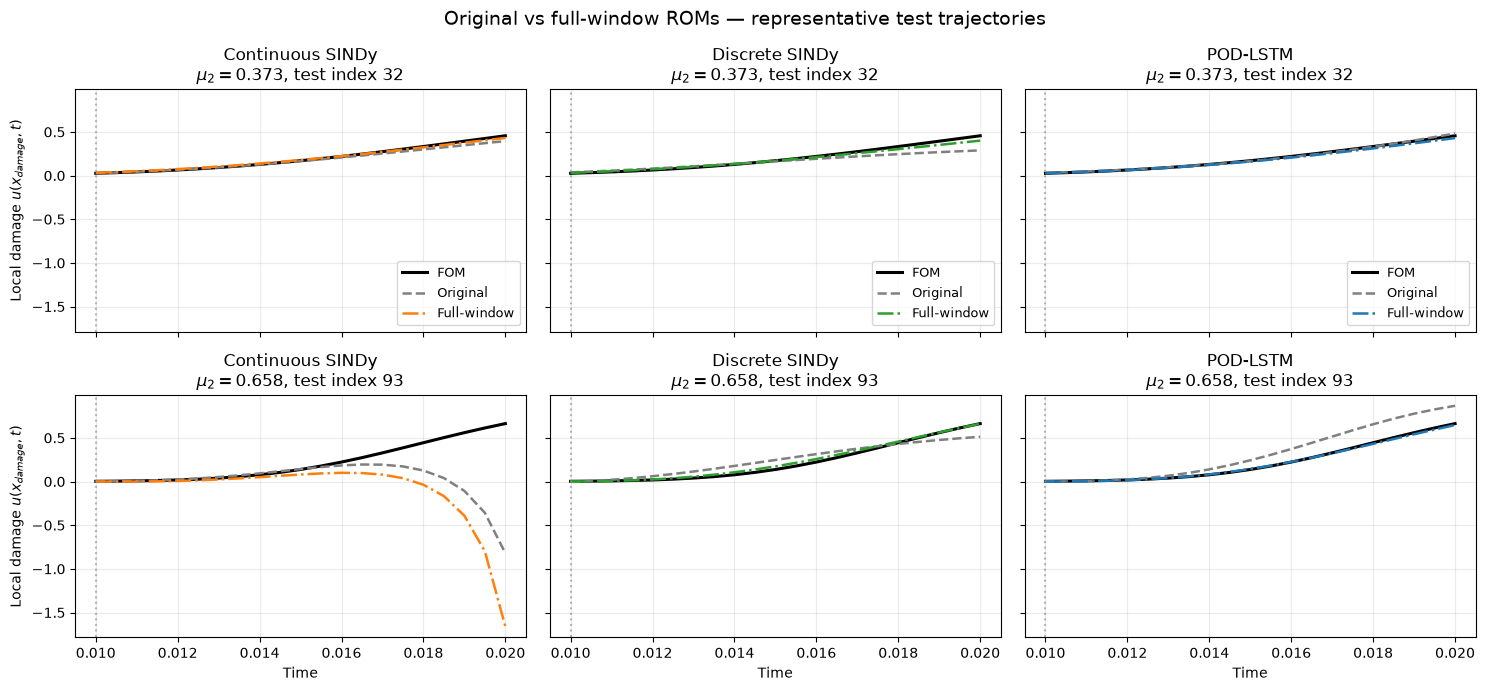

In [25]:
# Compare original and full-window ROM predictions on the same two
# representative test trajectories, using the same local damage probe.

model_dir = Path("artifacts/final_dynamics/selected")
with open(model_dir / "selected_configs.json") as f:
    full_configs = json.load(f)

# Load selected full-window models.
# Load the SINDy coefficients and quadratic feature indices.
with np.load(model_dir / "continuous_sindy.npz") as data:
    Xi_full = data["Xi"]
    pairs_full = np.asarray(
        data["quadratic_pairs"], dtype=int
    )

with np.load(
    model_dir / "discrete_sindy.npz", allow_pickle=True
) as data:
    discrete_full = {
        k: data[k].item() if data[k].ndim == 0 else data[k]
        for k in data.files
    }

checkpoint = torch.load(
    model_dir / "pod_lstm.pt",
    map_location="cpu",
    weights_only=False
)

lstm_cfg = checkpoint["config"]
lstm_scaling_full = checkpoint["scaling"]
lstm_full = ef.ParametricPODLSTM.build(
    n_modes=lstm_cfg["n_modes"],
    hidden_size=lstm_cfg["hidden_size"]
).to(device)
lstm_full.load_state_dict(checkpoint["state_dict"])
lstm_full.eval()

print("Selected LSTM checkpoint epoch:", checkpoint["best_epoch"])

# Keep the same representative test cases as in the original figure.
old_names = ["Continuous SINDy", "Discrete SINDy", "POD-LSTM"]

common = np.ones(len(test_idx), dtype=bool)
for name in old_names:
    common &= np.asarray(test_results[name]["success"], dtype=bool)

pool = np.asarray(test_idx)[common]
if len(pool) < 2:
    raise RuntimeError("Insufficient common-success test trajectories.")

targets = [0.373, 0.708]
case_ids = []
for target in targets:
    candidates = [idx for idx in pool if idx not in case_ids]
    chosen = min(
        candidates,
        key=lambda idx: abs(mu_fom[idx, 1] - target)
    )
    case_ids.append(int(chosen))

# Evaluate POD modes at the original damage-sensitive point.
x_damage = (2.75866689, 4.71215822)
probe = df.Function(Vh)
point = df.Point(*x_damage)

point_modes = np.empty(Vn.shape[1])
for j in range(Vn.shape[1]):
    probe.vector().set_local(np.asarray(Vn[:, j], dtype=float))
    probe.vector().apply("insert")
    point_modes[j] = float(probe(point))

def point_fom(idx):
    """Return the FOM observation curve for trajectory idx from the forecast split onward."""
    values = []
    for field in u_fom[idx, split_idx:]:
        probe.vector().set_local(np.asarray(field, dtype=float))
        probe.vector().apply("insert")
        values.append(float(probe(point)))
    return np.asarray(values)

times = np.asarray(sensor_times)[split_idx:]
n_steps = len(times) - 1

def forecast_to_curve(coefficients, n_modes):
    """Convert a valid coefficient forecast to the sensor curve, accepting an optional initial anchor."""
    if coefficients is None:
        return None

    a = np.asarray(coefficients, dtype=float)
    if a.ndim != 2 or a.shape[1] != n_modes:
        return None

    if a.shape[0] == n_steps:
        return a @ point_modes[:n_modes]

    if a.shape[0] == n_steps + 1:
        return a @ point_modes[:n_modes]

    return None

def plot_prediction(ax, values, style, label, color):
    """Plot a finite sensor forecast against matching times; return False for unavailable predictions."""
    if values is None:
        return False

    # A forecast without the initial anchor starts at times[1].
    t = times if len(values) == len(times) else times[1:]

    if not np.isfinite(values).all():
        return False

    ax.plot(
        t, values, style,
        color=color, linewidth=1.8, label=label
    )
    return True

models = ["Continuous SINDy", "Discrete SINDy", "POD-LSTM"]
new_colors = ["tab:orange", "tab:green", "tab:blue"]

fig, axes = plt.subplots(
    2, 3, figsize=(15, 7), sharex=True, sharey=True
)

for row, idx in enumerate(case_ids):
    mu = mu_fom[idx]
    fom_point = point_fom(idx)

    # Full-window predictions from the exact FOM state at T/2.
    new_predictions = {}

    try:
        new_predictions["Continuous SINDy"] = ef.simulate_sindy(
            A_fom[idx, split_idx, :Xi_full.shape[1]],
            mu, Xi_full, times, pairs_full
        )
    except (ValueError, RuntimeError, FloatingPointError, OverflowError):
        new_predictions["Continuous SINDy"] = None

    n_discrete = int(full_configs["Discrete_SINDy"]["n_modes"])
    try:
        new_predictions["Discrete SINDy"] = (
            ef.rollout_discrete_sindy(
                discrete_full,
                A_fom[idx, split_idx, :n_discrete],
                mu, n_steps
            )
        )
    except (ValueError, RuntimeError, FloatingPointError, OverflowError):
        new_predictions["Discrete SINDy"] = None

    n_lstm = int(lstm_cfg["n_modes"])
    p = int(lstm_cfg["seq_len"])
    try:
        new_predictions["POD-LSTM"] = ef.rollout_pod_lstm(
            lstm_full,
            A_fom[idx, split_idx-p+1:split_idx+1, :n_lstm],
            mu,
            lstm_scaling_full,
            n_steps,
            device=device
        )
    except (ValueError, RuntimeError, FloatingPointError, OverflowError):
        new_predictions["POD-LSTM"] = None

    for col, (name, color) in enumerate(zip(models, new_colors)):
        ax = axes[row, col]
        ax.plot(
            times, fom_point, "k-",
            linewidth=2.2, label="FOM"
        )

        # Retrieve original benchmark forecasts (no retraining).
        original = test_results[name]["forecasts"].get(idx)
        original_n = test_results[name]["n_modes"]

        old_curve = forecast_to_curve(original, original_n)
        plot_prediction(
            ax, old_curve, "--", "Original", "0.5"
        )

        new_n = (
            Xi_full.shape[1] if name == "Continuous SINDy"
            else n_discrete if name == "Discrete SINDy"
            else n_lstm
        )
        new_curve = forecast_to_curve(
            new_predictions[name], new_n
        )
        plotted = plot_prediction(
            ax, new_curve, "-.", "Full-window", color
        )

        if not plotted:
            ax.text(
                0.5, 0.08, "Full-window forecast failed",
                transform=ax.transAxes,
                ha="center", color=color, fontsize=9
            )

        ax.set_title(
            f"{name}\n"
            f"$\\mu_2={mu[1]:.3f}$, test index {idx}"
        )
        ax.grid(alpha=0.25)
        ax.axvline(times[0], color="0.6", linestyle=":", alpha=0.7)

        if row == 1:
            ax.set_xlabel("Time")
        if col == 0:
            ax.set_ylabel("Local damage $u(x_{damage},t)$")
        if row == 0:
            ax.legend(fontsize=9)

fig.suptitle(
    "Original vs full-window ROMs — representative test trajectories",
    fontsize=14
)
fig.tight_layout()
plt.show()


**Effect on the illustrative trajectories.**

The original and full-window models are compared at the same diagnostic point for $\mu_{2}=0.373$ and $0.658$ (test indices 32 and 93), starting from FOM-projected states or histories at $T/2$.

In these two cases, full-window discrete SINDy and LSTM follow the reference more closely, particularly in the higher-reaction trajectory. Continuous SINDy follows the moderate case but develops a strongly negative prediction in the higher-reaction case. Its displayed trajectory reaches $T$, so the problem here is prediction quality and physical admissibility rather than an incomplete integration.

The improvement of discrete SINDy and LSTM concerns the displayed cases within the training time range. It does not establish an improvement over the entire test set or accuracy beyond $T$.


### 6.3 POD-NN history reconstruction

We restore the original network, coefficient scaling, POD basis and inferred parameters from Problem III. Comparing its sensor response with the saved inverse-problem prediction checks that the same surrogate has been reconstructed; this is a consistency check, not an independent FOM accuracy test.

The reconstructed history supplies the final state for DMD, SINDy and Galerkin, and the recent sequence for LSTM. Each model retains its own number of coefficients, so a common source history does not imply identical initial reconstructed fields.


In [26]:
# Recover the identified parameters and the original POD-NN surrogate.
# Reconstruct the history on [0,T] and verify it against Problem III.
artifacts = Path("artifacts")

required = [
    "inverse_results.npz",
    "pod_basis.npy",
    "scaler.npz",
    "pod_nn_model.pt",
]
missing = [f for f in required if not (artifacts / f).exists()]
if missing:
    raise FileNotFoundError(f"Missing Problem III artifacts: {missing}")

# Identified parameters and original sensor prediction.
with np.load(artifacts / "inverse_results.npz") as data:
    mu_opt = np.asarray(data["mu_opt"], dtype=float).reshape(3)
    t_history = np.asarray(data["sensor_times"], dtype=float)
    sensor_reference = np.asarray(
        data["prediction_opt"], dtype=float
    ).ravel()
    physical_saved = np.array([
        float(data[k]) for k in ("D_opt", "r_opt", "delta_opt")
    ])

physical_opt = np.array([
    10.0 ** mu_opt[0],
    10.0 ** (mu_opt[1] + 2.0),
    mu_opt[2] + 1.0,
])

if not np.isfinite(mu_opt).all() or np.any((mu_opt < 0) | (mu_opt > 1)):
    raise ValueError("Invalid identified parameters.")

if not np.allclose(physical_opt, physical_saved):
    raise ValueError("Inconsistent physical parameters in Problem III.")

if t_history.shape != sensor_times.shape or not np.allclose(
    t_history, sensor_times
):
    raise ValueError("Problem III and ROM time grids are inconsistent.")

T = float(t_history[-1])
dt_forecast = float(t_history[1] - t_history[0])
n_future = len(t_history) - 1
t_future = T + dt_forecast * np.arange(n_future + 1)

# Restore the exact POD basis and coefficient normalization.
V_identified = np.load(artifacts / "pod_basis.npy")

if V_identified.shape != Vn.shape or not np.allclose(
    V_identified, Vn
):
    raise ValueError("The saved POD basis differs from the ROM basis.")

with np.load(artifacts / "scaler.npz") as data:
    nn_scaler = sf.CoefficientScaler(
        minimum=data["minimum"],
        scale=data["scale"]
    )

pod_nn = sf.build_model(
    input_dim=4,
    output_dim=V_identified.shape[1],
    hidden_layers=(128,) * 5,
    activation="silu",
    device="cpu"
)

checkpoint = torch.load(
    artifacts / "pod_nn_model.pt",
    map_location="cpu",
    weights_only=False
)
pod_nn.load_state_dict(checkpoint["state_dict"])
pod_nn.eval()
pod_nn.requires_grad_(False)

# Important: use ONLY [0,T] to preserve the NN time normalization.
X_opt = sf.make_nn_inputs(mu_opt[None, :], t_history)
A_muopt = sf.predict_coefficients(pod_nn, X_opt, nn_scaler)

if (
    A_muopt.shape != (len(t_history), V_identified.shape[1])
    or not np.isfinite(A_muopt).all()
):
    raise ValueError("Invalid POD-NN coefficient history.")

# Evaluate the POD basis at the sensor and target locations.
probe = df.Function(Vh)

def pod_modes_at_point(coordinates):
    """Return the identified POD basis functions evaluated at the supplied spatial coordinates."""
    point = df.Point(*coordinates)
    values = np.empty(V_identified.shape[1])

    for j in range(V_identified.shape[1]):
        probe.vector().set_local(V_identified[:, j])
        probe.vector().apply("insert")
        values[j] = float(probe(point))

    return values

sensor_modes = pod_modes_at_point((0.5, 3.0))
target_modes = pod_modes_at_point((3.5, 2.0))

sensor_reconstructed = A_muopt @ sensor_modes
u_target_history = A_muopt @ target_modes

# Confirm that this is the same surrogate used for identification.
sensor_difference = np.max(
    np.abs(sensor_reconstructed - sensor_reference)
)

if not np.allclose(
    sensor_reconstructed, sensor_reference,
    rtol=1e-4, atol=1e-5
):
    raise ValueError(
        "POD-NN reconstruction does not match Problem III."
    )

print("Identified parameters:", mu_opt)
print(
    f"D = {physical_opt[0]:.6g}, "
    f"r = {physical_opt[1]:.6g}, "
    f"delta = {physical_opt[2]:.6g}"
)
print(f"Sensor consistency: max difference = {sensor_difference:.2e}")
print(f"History: [0, {T:.4f}] ({len(t_history)} snapshots)")
print(f"Forecast: ({T:.4f}, {t_future[-1]:.4f}] ({n_future} steps)")
print(f"u_POD-NN(x*, T) = {u_target_history[-1]:.6f}")


Identified parameters: [0.4010064  0.89656759 0.89816353]
D = 2.51771, r = 788.075, delta = 1.89816
Sensor consistency: max difference = 1.35e-07
History: [0, 0.0200] (41 snapshots)
Forecast: (0.0200, 0.0400] (40 steps)
u_POD-NN(x*, T) = -0.011762


The identified parameters are

$$
\mu_{\mathrm{opt}}\approx(0.401006,0.896568,0.898164),
\qquad D\approx2.51771,\quad r\approx788.075,\quad\delta\approx1.89816.
$$

The reaction rate remains within the difficult high-reaction regime. The restored sensor prediction differs from the saved response by at most $1.35\times10^{-7}$.

At the target point,

$$
\widehat u_{\mathrm{NN}}(x^{\ast},T)\approx-0.011762.
$$

This prediction is close to zero but slightly negative and therefore physically inadmissible. It is retained without clipping. The surrogate suggests little local damage at the end of the observed window, but its sign and magnitude do not establish the true pointwise damage. The following diagnostics examine both the local curve and spatial extrema.


### 6.4 Pointwise forecast and model completion

Propagate the selected models from the POD-NN history at $T$ to $2T$. Evaluate the requested point $x^{\ast}=(3.5,2)$ and report integration failures alongside completed forecasts.


Continuous SINDy: Failed: RuntimeError: Integration returned None
POD-Galerkin: Failed: RuntimeError: Integration returned None


,Model,Status,"u(x*,T)","u(x*,2T)",Min local u,Max local u,Admissible
0,DMD,Completed,-0.01176,0.04233,-0.01687,0.05472,False
1,Continuous SINDy,Failed: RuntimeError: Integration returned None,NaN,NaN,NaN,NaN,False
2,POD-Galerkin,Failed: RuntimeError: Integration returned None,NaN,NaN,NaN,NaN,False
3,POD-LSTM,Completed,-0.01527,1.16560,-0.01527,1.20853,False
4,Discrete SINDy,Completed,0.02170,1.27613,0.02170,1.28273,False


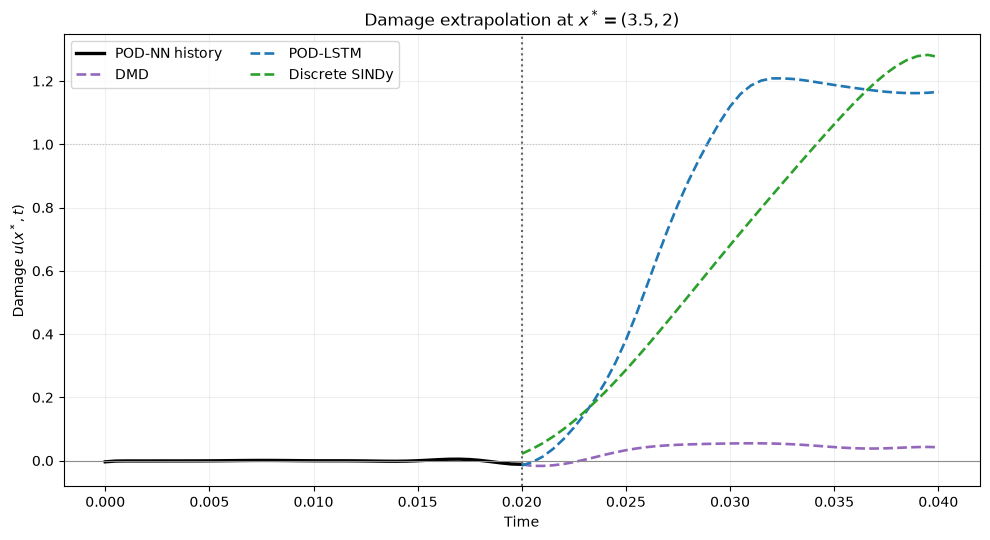


Forecast completion:
  DMD: Completed
  Continuous SINDy: Failed: RuntimeError: Integration returned None
  POD-Galerkin: Failed: RuntimeError: Integration returned None
  POD-LSTM: Completed
  Discrete SINDy: Completed


In [27]:
# Extrapolate all selected ROMs from T to 2T using the identified POD-NN
# history. Preserve failures and non-physical values without clipping.
n_steps = len(t_future) - 1
a_T = A_muopt[-1]
forecasts_2T = {}
forecast_status = {}

def store_forecast(name, predicted, n_modes):
    """Validate a coefficient forecast, prepend the common state at T when needed, and store its status."""
    if predicted is None:
        raise RuntimeError("Integration returned None")

    a = np.asarray(predicted, dtype=float)

    if a.ndim != 2 or a.shape[1] != n_modes:
        raise ValueError(f"Unexpected forecast shape: {a.shape}")

    if len(a) == n_steps:
        a = np.vstack([a_T[:n_modes], a])
    elif len(a) != n_steps + 1:
        raise ValueError(f"Unexpected forecast length: {len(a)}")

    if not np.isfinite(a).all():
        raise ValueError("Non-finite forecast coefficients")

    forecasts_2T[name] = a
    forecast_status[name] = "Completed"

def attempt(name, n_modes, function):
    """Run and store one forecast, recording its exception as a failed status instead of stopping the comparison."""
    try:
        store_forecast(name, function(), n_modes)
    except Exception as exc:
        forecasts_2T[name] = None
        forecast_status[name] = (
            f"Failed: {type(exc).__name__}: {str(exc)[:90]}"
        )
        print(f"{name}: {forecast_status[name]}")

# DMD: fit on the complete POD-NN history, using the selected rank.
dmd_rank = int(full_configs["DMD"]["rank"])
dmd_start = int(full_configs["DMD"]["start_idx"])

def forecast_dmd():
    """Return the DMD coefficient forecast using the enclosing observation window and rank settings."""
    model = ef.fit_dmd(
        A_muopt, rank=dmd_rank, start_idx=dmd_start
    )
    return ef.predict_dmd(model, a_T, n_steps)

attempt("DMD", A_muopt.shape[1], forecast_dmd)

# Continuous SINDy: integrate the selected full-window vector field.
n_cont = Xi_full.shape[1]
attempt(
    "Continuous SINDy", n_cont,
    lambda: ef.simulate_sindy(
        a_T[:n_cont], mu_opt, Xi_full, t_future, pairs_full
    )
)

# POD-Galerkin: integrate the physics-based reduced system.
n_gal = 50
attempt(
    "POD-Galerkin", n_gal,
    lambda: ef.simulate_galerkin(
        a_T[:n_gal], mu_opt,
        K_galerkin[:n_gal, :n_gal],
        C_galerkin[:n_gal, :n_gal, :n_gal],
        t_future
    )
)

# POD-LSTM: initialize with the last p POD-NN states.
n_lstm = int(lstm_cfg["n_modes"])
p_lstm = int(lstm_cfg["seq_len"])

attempt(
    "POD-LSTM", n_lstm,
    lambda: ef.rollout_pod_lstm(
        lstm_full,
        A_muopt[-p_lstm:, :n_lstm],
        mu_opt,
        lstm_scaling_full,
        n_steps,
        device=device
    )
)

# Discrete SINDy: propagate the learned one-step map.
n_disc = int(full_configs["Discrete_SINDy"]["n_modes"])

attempt(
    "Discrete SINDy", n_disc,
    lambda: ef.rollout_discrete_sindy(
        discrete_full, a_T[:n_disc], mu_opt, n_steps
    )
)

# Reconstruct target-point damage and summarize final predictions.
target_forecasts = {}
rows = []

for name, a in forecasts_2T.items():
    if a is None:
        rows.append({
            "Model": name,
            "Status": forecast_status[name],
            "u(x*,T)": np.nan,
            "u(x*,2T)": np.nan,
            "Min local u": np.nan,
            "Max local u": np.nan,
            "Admissible": False
        })
        continue

    n = a.shape[1]
    u_local = a @ target_modes[:n]
    target_forecasts[name] = u_local

    rows.append({
        "Model": name,
        "Status": "Completed",
        "u(x*,T)": u_local[0],
        "u(x*,2T)": u_local[-1],
        "Min local u": u_local.min(),
        "Max local u": u_local.max(),
        "Admissible": bool(
            np.all((u_local >= 0) & (u_local <= 1))
        )
    })

final_damage_table = pd.DataFrame(rows)
display(final_damage_table.round(5))

# Plot the common POD-NN history and all successful forecasts.
fig, ax = plt.subplots(figsize=(10, 5.5))

ax.plot(
    t_history, u_target_history,
    color="black", linewidth=2.4,
    label="POD-NN history"
)

colors = {
    "DMD": "tab:purple",
    "Continuous SINDy": "tab:orange",
    "POD-Galerkin": "tab:red",
    "POD-LSTM": "tab:blue",
    "Discrete SINDy": "tab:green",
}

for name, u_local in target_forecasts.items():
    ax.plot(
        t_future, u_local,
        linewidth=1.9, linestyle="--",
        color=colors[name],
        label=name
    )

ax.axvline(T, color="0.4", linestyle=":", linewidth=1.5)
ax.axhline(0, color="0.55", linewidth=0.8)
ax.axhline(1, color="0.75", linewidth=0.8, linestyle=":")

ax.set(
    xlabel="Time",
    ylabel=r"Damage $u(x^*,t)$",
    title=r"Damage extrapolation at $x^*=(3.5,2)$"
)
ax.grid(alpha=0.2)
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

print("\nForecast completion:")
for name, status in forecast_status.items():
    print(f"  {name}: {status}")


**Prediction at the requested point and time.**

| Model | Predicted damage at the target at 2T | Outcome |
|---|---:|---|
| DMD | 0.0423 | Completed; spatial field contains large nonphysical values |
| Continuous SINDy | — | Integration did not complete |
| POD-Galerkin | — | Integration did not complete |
| POD-LSTM | 1.1656 | Completed; exceeds physical saturation |
| Discrete SINDy | 1.2761 | Completed; exceeds physical saturation |

LSTM and discrete SINDy predict a substantial increase from their near-zero local states at $T$ to values above saturation at $2T$. Taken qualitatively, these two forecasts suggest that significant damage could reach the target during $(T,2T]$ and approach the saturated regime by the requested time. Their values above 1 cannot be interpreted as physical damage intensities, and their agreement is not an independent verification because they share training data and the POD representation.

DMD instead predicts a low local value, approximately 0.0423. Its strongly inadmissible spatial field prevents treating this as reliable evidence that the target remains only weakly damaged. Continuous SINDy and Galerkin provide no completed estimate at $2T$.

**The model-based indication is a possible transition to substantial, near-saturated damage by $2T$, supported by LSTM and discrete SINDy.** This is an unvalidated scenario: model disagreement and physical violations prevent confirming arrival, assigning a trustworthy intensity, or identifying an arrival time. Clipping the predictions to 1 would conceal the overshoot without validating saturation.


### 6.5 Spatial admissibility and damage evolution

Reconstruct the seed fields and completed forecasts to examine extrema and the fraction of nodal values outside $[0,1]$. Animate the spatial evolution over $[0,2T]$, using FEM-aware visualization.


In [28]:
# Diagnose full-field admissibility at T and during extrapolation.
# Distinguish errors inherited from POD-NN from dynamical overshoots.

import numpy as np
import pandas as pd
import support_functions as sf

diagnostics = []

# Shared POD-NN state, reconstructed with different reduced dimensions.
for n in [10, 20, 50]:
    field = sf.reconstruct_pod(A_muopt[-1, :n], Vn[:, :n])

    diagnostics.append({
        "Model": f"POD-NN seed (N={n})",
        "Time": T,
        "Field min": float(np.min(field)),
        "Field max": float(np.max(field)),
        "DOFs < 0 [%]": 100 * np.mean(field < 0),
        "DOFs > 1 [%]": 100 * np.mean(field > 1),
    })

# Reconstruct completed ROM forecasts at selected times.
for name, coefficients in forecasts_2T.items():
    if coefficients is None:
        continue

    n = coefficients.shape[1]

    for step in [0, n_steps // 2, n_steps]:
        field = sf.reconstruct_pod(
            coefficients[step], Vn[:, :n]
        )

        diagnostics.append({
            "Model": name,
            "Time": float(t_future[step]),
            "Field min": float(np.min(field)),
            "Field max": float(np.max(field)),
            "DOFs < 0 [%]": 100 * np.mean(field < 0),
            "DOFs > 1 [%]": 100 * np.mean(field > 1),
        })

field_diagnostics = pd.DataFrame(diagnostics)
display(field_diagnostics.round(4))


,Model,Time,Field min,Field max,DOFs < 0 [%],DOFs > 1 [%]
0,POD-NN seed (N=10),0.02,-0.0717,1.1018,26.2055,22.5588
1,POD-NN seed (N=20),0.02,-0.0435,1.0455,13.8035,19.6655
2,POD-NN seed (N=50),0.02,-0.0177,1.0396,16.8776,14.7981
3,DMD,0.02,-0.0177,1.0396,16.8776,14.7981
4,DMD,0.03,-0.3915,1.8559,17.4352,14.1652
5,DMD,0.04,-2.0500,1.2155,30.8469,4.0687
6,POD-LSTM,0.02,-0.0435,1.0455,13.8035,19.6655
7,POD-LSTM,0.03,0.0458,1.2022,0.0000,40.1145
8,POD-LSTM,0.04,0.4214,1.9298,0.0000,59.5690
9,Discrete SINDy,0.02,-0.0717,1.1018,26.2055,22.5588


In [34]:
# Animate FEM-consistent spatial damage fields on [0, 2T].
# Use the same FEM-aware plotting routine as in Problem III.

import numpy as np
import matplotlib.pyplot as plt
import dlroms.fespaces as fe
from dlroms.fespaces import gifs
from IPython.display import Image, display
import support_functions as sf

models = ["DMD", "POD-LSTM", "Discrete SINDy", "Continuous SINDy", "POD-Galerkin"]
times_full = np.concatenate([t_history, t_future[1:]])
n_history = len(t_history)

# Precompute complete fields to avoid repeated POD reconstructions.
history_fields = sf.reconstruct_pod(A_muopt, Vn)

model_fields = {}
for name in models:
    coefficients = forecasts_2T[name]
    if coefficients is None:
        name = None
        continue

    n = coefficients.shape[1]
    predicted_fields = sf.reconstruct_pod(
        coefficients, Vn[:, :n]
    )

    # The model-specific forecast starts at T.
    model_fields[name] = np.concatenate(
        [history_fields[:-1], predicted_fields],
        axis=0
    )

# Fixed visualization range, shared across all models.
levels = np.linspace(-0.05, 1.10, 120)


# Use one external colorbar shared by all four panels and all frames.

import matplotlib as mpl

# Global range over the entire animation, without clipping the data.
all_fields = [history_fields] + [
    field for field in model_fields.values()
    if field is not None
]

global_min = min(float(np.nanmin(a)) for a in all_fields)
global_max = max(float(np.nanmax(a)) for a in all_fields)

levels = np.linspace(global_min - 1e-6, global_max + 1e-6, 120)
norm = mpl.colors.Normalize(vmin=levels[0], vmax=levels[-1])
cmap = plt.get_cmap("viridis")


# Display the POD-NN history and all five ROMs in a 2x3 layout.
# Use one shared colorbar outside the panels.

def draw_final_damage(i):
    """Return a figure comparing final extrapolated damage fields for the selected models."""
    fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))

    fig.subplots_adjust(
        left=0.04, right=0.86,
        bottom=0.06, top=0.88,
        wspace=0.16, hspace=0.30
    )

    t = times_full[i]

    panels = [
        ("POD-NN history", history_fields[min(i, n_history - 1)]),
        *[
            (name, model_fields.get(name, None))
            for name in models
        ]
    ]

    for ax, (name, fields) in zip(axes.flat, panels):
        field = (
            fields if name == "POD-NN history"
            else None if fields is None else fields[i]
        )

        if field is None:
            ax.set_facecolor("#f5f5f5")
            ax.text(
                0.5, 0.55,
                name,
                transform=ax.transAxes,
                ha="center", va="center",
                fontsize=13, fontweight="bold"
            )
            ax.text(
                0.5, 0.40,
                "Forecast unavailable\nNumerical integration failed",
                transform=ax.transAxes,
                ha="center", va="center",
                fontsize=10, color="dimgray"
            )
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
            continue

        plt.sca(ax)
        fe.plot(field, Vh, cmap="viridis", levels=levels)

        ax.plot(
            3.5, 2.0, "r*",
            markersize=9,
            markeredgecolor="white",
            markeredgewidth=0.8
        )

        ax.set_title(
            f"{name} | t = {t:.4f}\n"
            f"min={field.min():.3f}, max={field.max():.3f}",
            fontsize=10
        )
        ax.set_aspect("equal")
        ax.set_xticks([])
        ax.set_yticks([])

    # One colorbar shared by all six panels.
    cax = fig.add_axes([0.90, 0.15, 0.02, 0.67])

    sm = mpl.cm.ScalarMappable(
        norm=norm,
        cmap="viridis"
    )
    sm.set_array([])

    cbar = fig.colorbar(sm, cax=cax)
    cbar.set_label(r"Damage $u(x,t)$")

    phase = (
        "POD-NN reconstruction"
        if i < n_history
        else "ROM extrapolation"
    )

    fig.suptitle(
        f"Damage evolution | {phase}",
        fontsize=14
    )

    return fig



from pathlib import Path

gif_path = Path(
    "artifacts/final_dynamics/gifs/damage_evolution_corrected.gif"
)

if not gif_path.exists():
    gif_path.parent.mkdir(parents=True, exist_ok=True)

    gifs.save(
        draw_final_damage,
        len(times_full),
        str(gif_path)
    )

    print(f"GIF generated: {gif_path}")

else:
    print(f"GIF already exists — skipping: {gif_path}")

GIF generated: artifacts/final_dynamics/gifs/damage_evolution_corrected.gif


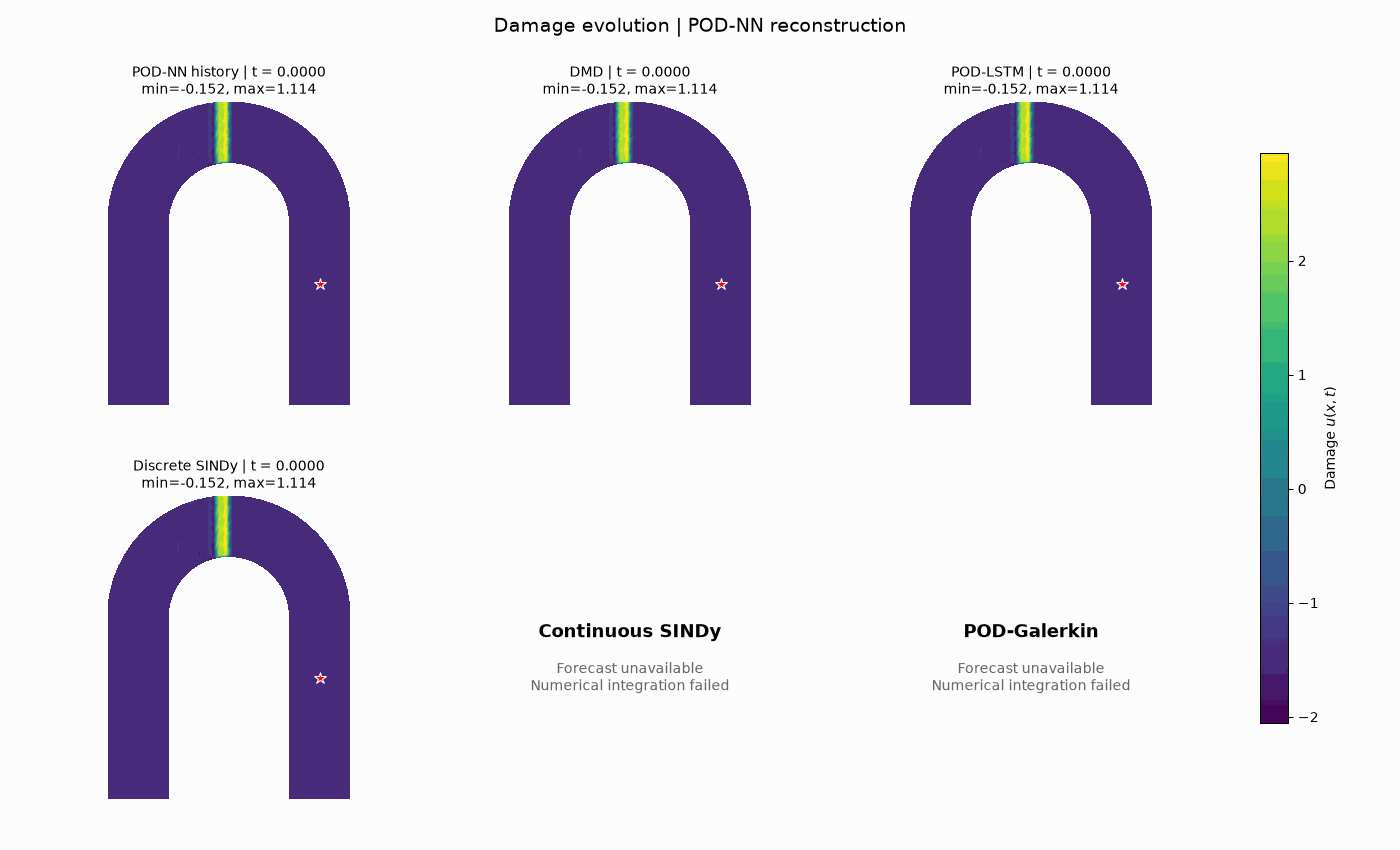

In [39]:
display(Image(
    filename="artifacts/final_dynamics/gifs/damage_evolution_corrected.gif"
))


**Spatial admissibility.**

At $2T$, DMD has nodal values approximately **−2.05–1.22**, LSTM **0.42–1.93**, and discrete SINDy **0.07–2.94**. The overshoots therefore extend beyond the point of interest. Approximately **59.57%** of LSTM nodal values and **50.00%** of discrete-SINDy nodal values exceed 1 at that time. These are fractions of FEM degrees of freedom, rather than area fractions of the domain.

The seed fields already violate the bounds to a lesser extent, so both reconstruction and subsequent propagation contribute to the admissibility problem. These violations concern the completed forecasts at the identified target parameters; continuous SINDy and Galerkin do not complete this forecast.


### 6.6 Sensitivity to the reaction regime

Repeat the forecast with $\mu_{2}=0.2$, retaining diffusion, initial damage location and the globally trained models. Reconstruct a new POD-NN history and refit DMD to that history. This diagnostic examines reaction sensitivity; it does not replace the forecast at the inferred parameters.


In [36]:
# Repeat the 2T extrapolation at a lower reaction rate, keeping
# diffusion, initial damage location and all trained ROMs unchanged.

mu_low = mu_opt.copy()
mu_low[1] = 0.20

X_low = sf.make_nn_inputs(mu_low[None, :], t_history)
A_low = sf.predict_coefficients(pod_nn, X_low, nn_scaler)

a_low_T = A_low[-1]
low_forecasts = {}
low_status = {}

def run_low(name, n_modes, forecast_fn):
    """Run a lower-dimensional forecast and record its result or failure in the enclosing comparison."""
    try:
        result = forecast_fn()

        if result is None:
            raise RuntimeError("Integration returned None")

        result = np.asarray(result, dtype=float)

        if result.ndim != 2 or result.shape[1] != n_modes:
            raise ValueError(f"Unexpected shape: {result.shape}")

        if len(result) == n_steps:
            result = np.vstack([a_low_T[:n_modes], result])
        elif len(result) != n_steps + 1:
            raise ValueError(f"Unexpected forecast length: {len(result)}")

        if not np.isfinite(result).all():
            raise ValueError("Non-finite forecast")

        low_forecasts[name] = result
        low_status[name] = "Completed"

    except Exception as exc:
        low_forecasts[name] = None
        low_status[name] = f"Failed: {type(exc).__name__}: {exc}"

# DMD: re-identify on the new POD-NN history, using fixed rank/start.
run_low(
    "DMD", A_low.shape[1],
    lambda: ef.predict_dmd(
        ef.fit_dmd(
            A_low,
            rank=int(full_configs["DMD"]["rank"]),
            start_idx=int(full_configs["DMD"]["start_idx"])
        ),
        a_low_T, n_steps
    )
)

# Continuous SINDy: use the globally trained model.
run_low(
    "Continuous SINDy", Xi_full.shape[1],
    lambda: ef.simulate_sindy(
        a_low_T[:Xi_full.shape[1]],
        mu_low, Xi_full, t_future, pairs_full
    )
)

# POD-Galerkin: unchanged physical operators.
run_low(
    "POD-Galerkin", 50,
    lambda: ef.simulate_galerkin(
        a_low_T[:50], mu_low,
        K_galerkin[:50, :50],
        C_galerkin[:50, :50, :50],
        t_future
    )
)

# POD-LSTM: initialize using the last p low-reaction states.
run_low(
    "POD-LSTM", int(lstm_cfg["n_modes"]),
    lambda: ef.rollout_pod_lstm(
        lstm_full,
        A_low[-int(lstm_cfg["seq_len"]):, :int(lstm_cfg["n_modes"])],
        mu_low,
        lstm_scaling_full,
        n_steps,
        device=device
    )
)

# Discrete SINDy: use the previously trained one-step model.
run_low(
    "Discrete SINDy", int(full_configs["Discrete_SINDy"]["n_modes"]),
    lambda: ef.rollout_discrete_sindy(
        discrete_full,
        a_low_T[:int(full_configs["Discrete_SINDy"]["n_modes"])],
        mu_low, n_steps
    )
)

# Summarize local damage and full-field admissibility at 2T.
low_rows = []

for name, coefficients in low_forecasts.items():
    if coefficients is None:
        low_rows.append({
            "Model": name, "Status": low_status[name],
            "u(x*,2T)": np.nan,
            "Field min": np.nan, "Field max": np.nan
        })
        continue

    n = coefficients.shape[1]
    final_field = sf.reconstruct_pod(coefficients[-1], Vn[:, :n])

    low_rows.append({
        "Model": name,
        "Status": low_status[name],
        "u(x*,2T)": float(coefficients[-1] @ target_modes[:n]),
        "Field min": float(final_field.min()),
        "Field max": float(final_field.max())
    })

low_table = pd.DataFrame(low_rows)

print("Low-reaction parameters:", mu_low)
print(f"Reaction rate: r = {10**(mu_low[1] + 2):.2f}")
display(low_table.round(5))


Low-reaction parameters: [0.4010064  0.2        0.89816353]
Reaction rate: r = 158.49


,Model,Status,"u(x*,2T)",Field min,Field max
0,DMD,Completed,-0.01131,-0.79630,1.41562
1,Continuous SINDy,Completed,0.04133,0.00485,0.98856
2,POD-Galerkin,Completed,-0.00068,-0.00975,0.98770
3,POD-LSTM,Completed,0.00860,0.00229,1.00810
4,Discrete SINDy,Completed,-0.00535,-0.11794,0.99981


In [37]:

gif_path = Path("artifacts/final_dynamics/gifs/damage_evolution_low_reaction.gif")

if not gif_path.exists():

    models = ["DMD", "POD-LSTM", "Discrete SINDy", "Continuous SINDy", "POD-Galerkin"]

    history_fields = sf.reconstruct_pod(A_low, Vn)
    n_history = len(history_fields)
    times_full = np.concatenate([t_history, t_future[1:]])

    model_fields = {}

    for name in models:
        coefficients = low_forecasts[name]

        if coefficients is None:
            raise RuntimeError(
                f"{name} did not complete the low-reaction forecast."
            )

        n = coefficients.shape[1]
        predicted_fields = sf.reconstruct_pod(
            coefficients, Vn[:, :n]
        )

        model_fields[name] = np.concatenate(
            [history_fields[:-1], predicted_fields], axis=0
        )

    all_fields = [history_fields] + [
        model_fields[name] for name in models
    ]

    global_min = min(float(np.nanmin(a)) for a in all_fields)
    global_max = max(float(np.nanmax(a)) for a in all_fields)

    levels = np.linspace(global_min - 1e-6, global_max + 1e-6, 120)
    norm = mpl.colors.Normalize(vmin=levels[0], vmax=levels[-1])

    gif_path.parent.mkdir(parents=True, exist_ok=True)

    gifs.save(
        draw_final_damage,
        len(times_full),
        str(gif_path)
    )

    print(f"GIF generated: {gif_path}")

else:
    print(f"GIF already exists — skipping: {gif_path}")

GIF generated: artifacts/final_dynamics/gifs/damage_evolution_low_reaction.gif


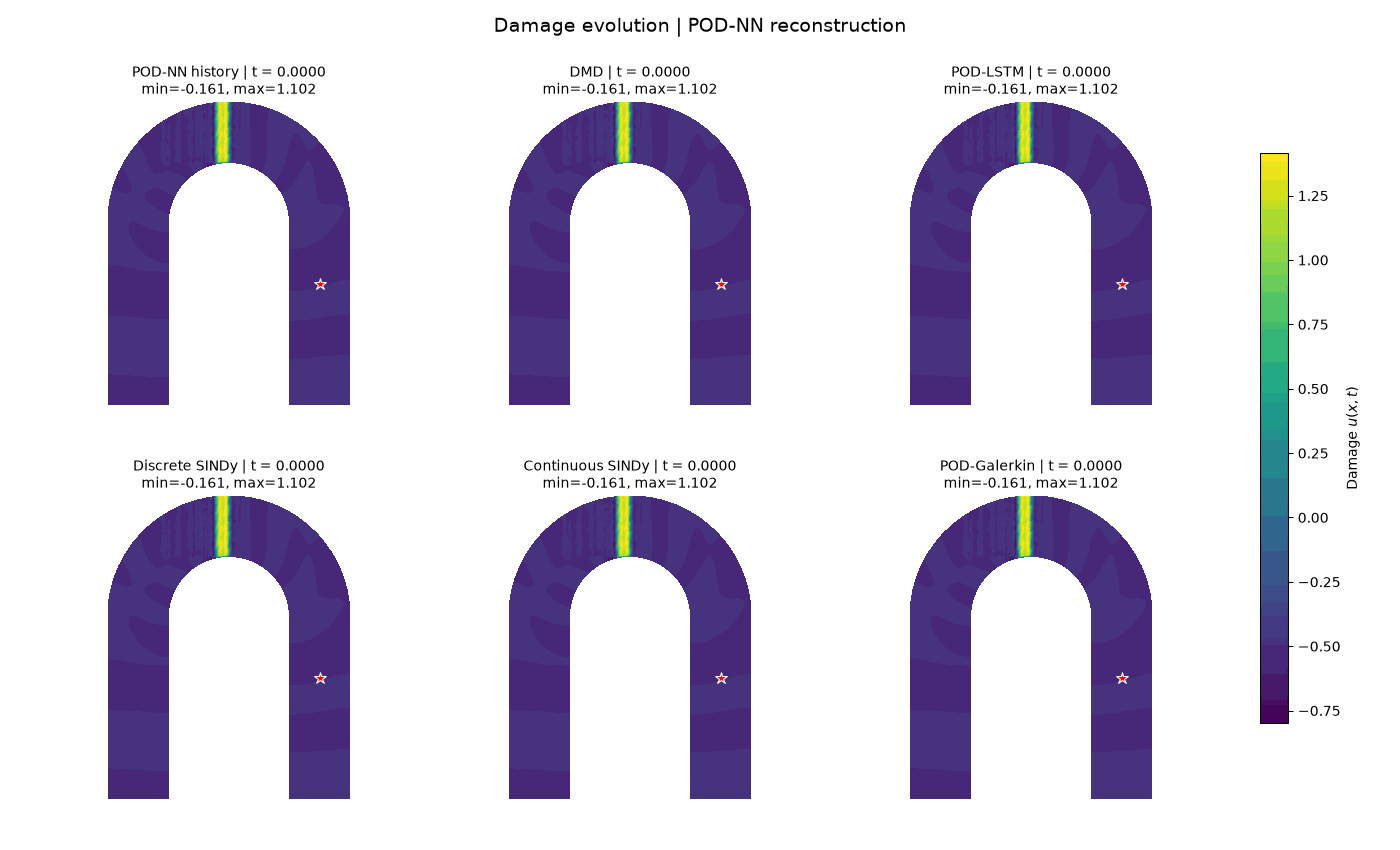

In [40]:
display(Image(
    filename="artifacts/final_dynamics/gifs/damage_evolution_low_reaction.gif"
))


**Reaction sensitivity.**

With $\mu_{2}=0.2$, all five models complete the forecast. Continuous SINDy gives approximately 0.0413 at the target and nodal extrema within $[0,1]$. Galerkin and LSTM give local values close to zero (approximately −0.0007 and 0.0086), with much smaller violations of the physical bounds than in the high-reaction forecast. DMD and discrete SINDy retain negative values in their spatial fields.

The more plausible behavior of continuous SINDy, Galerkin and LSTM supports sensitivity to the reaction regime. The parameter change also changes the POD-NN seed history, and DMD is refitted to that history. Thus, this comparison does not isolate the propagation dynamics from initialization, and plausible bounds alone do not verify accuracy without a reference solution.


## 7. Conclusions

The final parameters are $\mu_{\mathrm{opt}}\approx(0.401006,0.896568,0.898164)$, corresponding to $D\approx2.51771$, $r\approx788.075$ and $\delta\approx1.89816$. The reconstructed POD-NN history predicts little local damage at $x^{\ast}=(3.5,2)$ at $T=0.02$, although its value of approximately −0.0118 is slightly nonphysical.

**The forecasts provide a qualitative indication that substantial damage could reach the target by 2T and approach saturation.** LSTM and discrete SINDy predict a strong local increase, reaching approximately 1.1656 and 1.2761 at $2T=0.04$. These overshoots indicate a tendency toward high damage in the learned dynamics; they are not admissible estimates of its intensity. DMD predicts only 0.0423 and develops large spatial violations, while continuous SINDy and Galerkin fail to complete the forecast.

The answer to Problem IV is therefore conditional: **significant damage by the requested time is a scenario suggested by two learned models, but neither its arrival nor its intensity is validated by the present results.** No trustworthy numerical damage level or arrival time can be assigned. In particular, reporting a clipped value of 1 as confirmed saturation would overstate the evidence.

The initial temporal holdout reveals particularly weak reliability at high reaction. Full-window training improves the displayed discrete-SINDy and LSTM trajectories within the observed time range, but does not validate extrapolation beyond $T$. The final target has a higher reaction parameter than those illustrations, uses a POD-NN initial history, and requires a rollout twice as long.

The observed limitation involves the interaction between reduced representation, identified or projected dynamics, surrogate initialization and numerical propagation. A low POD reconstruction error need not preserve equilibrium or physical bounds, and a low derivative residual need not yield a stable autonomous trajectory. The present experiments do not isolate a unique cause for all failures.

A reference check beyond $T$, sensitivity to initialization and time discretization, and dynamics that better preserve saturation would be needed to assess the suggested high-damage scenario quantitatively. An explicit threshold for significant damage would also be needed to define an operational arrival time.
